# S&P 500 — Từ dữ liệu thị trường đến dự báo có kiểm chứng

**Câu hỏi nghiên cứu:** Giá và lợi suất đã thay đổi ra sao qua các chế độ thị trường? Biến động có tính dai dẳng không? Các đặc trưng tại cuối phiên hôm nay có giúp dự báo rủi ro **5 phiên tiếp theo** tốt hơn một quy tắc đơn giản không? Dự báo hướng đi ngày mai có thực sự hữu ích?

Notebook này kết hợp **kiểm tra dữ liệu → EDA → giả thuyết → mô hình → kiểm thử ngoài mẫu → giới hạn**. Các bảng và nhận xét định lượng được tạo từ dữ liệu đang chạy, thay vì ghi sẵn các tuyên bố về độ chính xác.

> **Phạm vi dữ liệu mặc định:** bộ S&P 500 theo ngày của Vega Datasets, từ 03/01/2000 đến 17/04/2020. Đây là dữ liệu giá thật nhưng đã cũ, dùng để tái lập nghiên cứu; kết quả không mô tả thị trường hiện tại. Có thể chọn CSV của bạn hoặc Yahoo Finance ở ô cấu hình. Không thay dữ liệu thiếu bằng dữ liệu mô phỏng.

## Bản đồ nội dung
1. Cấu hình, nguồn và chất lượng dữ liệu.
2. Bức tranh thị trường: lợi suất, drawdown, mùa vụ, đuôi phân phối và cụm biến động.
3. Đặc trưng, mục tiêu và chia tập theo thời gian có khoảng cách chống rò rỉ nhãn.
4. Dự báo biến động: baseline, HAR/Ridge, cây và PyTorch MLP.
5. Kiểm thử cuối cùng, sai số theo chế độ thị trường và diễn giải mô hình.
6. Bài toán phụ: hướng đi ngày mai, xác suất và độ tin cậy.
7. Tổng hợp insight, giới hạn và xuất kết quả.

## 1. Thiết kế nghiên cứu và những điểm được sửa

| Vấn đề của phiên bản trước | Cách xử lý trong notebook này |
|---|---|
| Một số import nằm sau nơi sử dụng; mô hình và biến bị định nghĩa lại | Import tập trung, tên biến nhất quán, chạy tuần tự từ kernel mới |
| Nhãn hướng đi ở dòng cuối vô tình trở thành 0 | Giữ nhãn tương lai chưa biết là thiếu và loại khỏi tập học |
| Dự báo biến động trượt ngày mai chồng lấn 9/10 phiên với hôm nay | Mục tiêu chính dùng **5 lợi suất hoàn toàn ở tương lai**; baseline là bắt buộc |
| Chỉ nhìn một tỷ lệ accuracy/R² | Đo RMSE, MAE, QLIKE, kỹ năng so với baseline; phân loại có balanced accuracy, AUC và Brier |
| Chọn mô hình theo cảm giác hoặc kết quả test | Chọn theo validation; đóng băng lựa chọn trước khi mở test |
| Nhãn nhiều ngày có thể vượt qua ranh giới tập | Loại H phiên trước các ranh giới và dùng `TimeSeriesSplit(gap=H)` |
| Không cố định hạt giống, chưa so sánh PyTorch với mô hình đơn giản | Cố định seed, early stopping, so sánh cùng dữ liệu và cùng mục tiêu |
| Kết luận “an toàn”, “độ chính xác cao” không đủ bằng chứng | Kết luận tự động từ kết quả; không suy ra hiệu quả đầu tư từ độ khớp mô hình |

**Thời điểm dự báo:** ngay sau khi phiên *t* đóng cửa. Giá và lợi suất của phiên *t* được phép dùng. Nếu muốn giao dịch trước khi đóng cửa, phải lùi toàn bộ đặc trưng một phiên.

In [1]:
# Cài thư viện trong môi trường riêng trước khi chạy, không pip install giữa notebook.
import os, io, json, time, hashlib, random, copy, platform
from pathlib import Path
from datetime import date, timedelta
from urllib.request import urlopen
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy import stats
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, balanced_accuracy_score, roc_auc_score, brier_score_loss,
    confusion_matrix, RocCurveDisplay)
from sklearn.calibration import calibration_curve
import torch
from torch import nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
pd.set_option('display.max_columns', 14)
versions = {name: metadata.version(name) for name in
            ['numpy', 'pandas', 'scipy', 'matplotlib', 'seaborn', 'scikit-learn', 'torch']}
display(pd.Series({'Python': platform.python_version(), **versions}, name='Phiên bản').to_frame())

,Phiên bản
Python,3.12.14
numpy,2.5.4
pandas,3.1.1
scipy,1.18.1
matplotlib,3.11.2
seaborn,0.13.2
scikit-learn,1.9.1
torch,2.15.0+cpu


### 1.1. Cấu hình nguồn dữ liệu

- `historical_sample` (mặc định): tải bản dữ liệu công khai **được ghim theo commit và SHA-256**, không cần tài khoản. Bộ dữ liệu này kết thúc tháng 04/2020.
- `csv`: dùng tệp của bạn; hỗ trợ CSV OHLCV thông thường hoặc CSV hai hàng tiêu đề từ `yfinance`. Tối thiểu cần ngày và giá đóng cửa; không tạo OHLC/Volume giả.
- `yahoo`: tải `^GSPC`; yêu cầu mạng cho Yahoo Finance. Nếu tải thất bại, notebook báo lỗi rõ ràng, **không âm thầm đổi nguồn**.

Chạy lại từ đầu sau khi thay cấu hình. Notebook chỉ phân tích **chỉ số giá** S&P 500, chưa bao gồm tái đầu tư cổ tức, phí, thuế hay tác động thị trường. CPU đủ cho các mô hình ở đây.

In [2]:
DATA_SOURCE = os.environ.get('SP500_DATA_SOURCE', 'historical_sample')
CSV_PATH = Path(os.environ.get('SP500_CSV', 'sp500_historical.csv'))
START_DATE = '2000-01-01'
END_DATE = (date.today() + timedelta(days=1)).isoformat()  # Yahoo: ngày kết thúc loại trừ
H = 5                  # số phiên tương lai của mục tiêu rủi ro
ANNUAL = 252
RUN_MLP = True
ARTIFACT_DIR = Path(os.environ.get('SP500_OUTPUT_DIR', 'outputs/sp500_research'))
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
SAMPLE_URL = ('https://raw.githubusercontent.com/vega/vega-datasets/'
              '5448e25297c8f705be78e879d5423d55d04dc6f1/data/sp500-2000.csv')
SAMPLE_SHA256 = '9409e9342d0657c747324e4cfabce8a8c7f663bc485b95a3378f36b0a160f8c8'
CACHE_PATH = ARTIFACT_DIR / 'sp500-2000.csv'


def read_price_csv(path_or_buffer):
    """Phát hiện CSV yfinance MultiIndex trước khi chuẩn hóa tên cột."""
    if isinstance(path_or_buffer, (str, Path)):
        raw = Path(path_or_buffer).read_bytes()
    else:
        raw = path_or_buffer.read()
    lines = raw.decode('utf-8-sig').splitlines()
    if len(lines) > 1 and lines[1].split(',')[0] == 'Ticker':
        frame = pd.read_csv(io.BytesIO(raw), header=[0, 1], index_col=0)
        tickers = set(frame.columns.get_level_values(1))
        if len(tickers) != 1:
            raise ValueError('CSV có nhiều mã. Hãy xuất riêng một chỉ số S&P 500.')
        frame.columns = frame.columns.get_level_values(0)
        frame.index = pd.to_datetime(frame.index, errors='raise')
        frame.index.name = 'Date'
        return frame.reset_index()
    return pd.read_csv(io.BytesIO(raw))


if DATA_SOURCE == 'historical_sample':
    payload = CACHE_PATH.read_bytes() if CACHE_PATH.exists() else urlopen(SAMPLE_URL, timeout=30).read()
    if hashlib.sha256(payload).hexdigest() != SAMPLE_SHA256:
        raise ValueError('Checksum dữ liệu mẫu không khớp. Không sử dụng dữ liệu chưa xác minh.')
    CACHE_PATH.write_bytes(payload)
    raw_data = read_price_csv(io.BytesIO(payload))
    provenance = {'source': DATA_SOURCE, 'url': SAMPLE_URL, 'sha256': SAMPLE_SHA256}
elif DATA_SOURCE == 'csv':
    raw_data = read_price_csv(CSV_PATH)
    provenance = {'source': 'csv', 'path': str(CSV_PATH),
                  'sha256': hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()}
elif DATA_SOURCE == 'yahoo':
    import yfinance as yf
    downloaded = yf.download('^GSPC', start=START_DATE, end=END_DATE,
                             auto_adjust=False, progress=False, threads=False, timeout=20)
    if downloaded.empty:
        raise RuntimeError('Yahoo trả dữ liệu rỗng. Kiểm tra mạng hoặc chọn CSV; không dùng kết quả rỗng.')
    if isinstance(downloaded.columns, pd.MultiIndex):
        downloaded.columns = downloaded.columns.get_level_values(0)
    raw_data = downloaded.reset_index()
    provenance = {'source': 'yahoo', 'ticker': '^GSPC', 'start_requested': START_DATE,
                  'end_exclusive': END_DATE, 'yfinance_version': metadata.version('yfinance')}
else:
    raise ValueError('DATA_SOURCE phải là historical_sample, csv hoặc yahoo.')
print('Nguồn dữ liệu:', provenance['source'])
display(raw_data.head())

Nguồn dữ liệu: historical_sample


,date,open,high,low,close,adjclose,volume
0,2000-01-03,1469.250000,1478.000000,1438.359985,1455.219971,1455.219971,931800000
1,2000-01-04,1455.219971,1455.219971,1397.430054,1399.420044,1399.420044,1009000000
2,2000-01-05,1399.420044,1413.270020,1377.680054,1402.109985,1402.109985,1085500000
3,2000-01-06,1402.109985,1411.900024,1392.099976,1403.449951,1403.449951,1092300000
4,2000-01-07,1403.449951,1441.469971,1400.729980,1441.469971,1441.469971,1225200000


In [3]:
# Chuẩn hóa và kiểm tra dữ liệu; không forward-fill giá trong ngày bị thiếu.
rename = {str(c): str(c).strip().lower().replace(' ', '_') for c in raw_data.columns}
prices = raw_data.rename(columns=rename).copy()
if 'date' not in prices.columns or 'close' not in prices.columns:
    raise ValueError('Cần cột Date và Close (không phân biệt hoa/thường).')
prices['date'] = pd.to_datetime(prices['date'], errors='raise', utc=True).dt.tz_convert(None).dt.normalize()
prices = prices.set_index('date').sort_index()
if prices.index.has_duplicates:
    raise ValueError('Ngày bị trùng: kiểm tra nguồn thay vì tự ý bỏ bản ghi.')
for column in prices.columns:
    prices[column] = pd.to_numeric(prices[column], errors='raise')
if prices['close'].isna().any() or (prices['close'] <= 0).any():
    raise ValueError('Close thiếu, bằng 0 hoặc âm. Cần sửa dữ liệu nguồn.')
if not np.isfinite(prices['close']).all():
    raise ValueError('Close có giá trị vô hạn.')
if len(prices) < 1000:
    raise ValueError('Cần ít nhất 1.000 phiên để chia tập, xem chế độ thị trường và đánh giá mô hình.')
median_gap = prices.index.to_series().diff().dt.days.median()
if median_gap > 3:
    raise ValueError('Dữ liệu có vẻ không phải theo ngày. Không áp dụng quy năm 252 cho dữ liệu tháng.')
if {'high', 'low', 'open'}.issubset(prices.columns):
    bad_ohlc = (prices['high'] < prices[['open', 'close', 'low']].max(axis=1)) | (prices['low'] > prices[['open', 'close', 'high']].min(axis=1))
    if bad_ohlc.any():
        raise ValueError(f'Có {bad_ohlc.sum()} dòng OHLC không nhất quán.')
returns = prices['close'].pct_change(fill_method=None)
log_returns = np.log(prices['close']).diff()
provenance.update({'first_date': str(prices.index.min().date()),
                   'last_date': str(prices.index.max().date()), 'rows': len(prices)})
if DATA_SOURCE == 'yahoo':
    provenance['normalized_csv_sha256'] = hashlib.sha256(prices.to_csv().encode()).hexdigest()
    prices.to_csv(ARTIFACT_DIR / 'downloaded_prices.csv')
(ARTIFACT_DIR / 'data_provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
quality = pd.DataFrame({
    'Chỉ tiêu': ['Phiên', 'Từ ngày', 'Đến ngày', 'Ngày trùng', 'Close thiếu',
                 'Khoảng cách lịch lớn nhất (ngày)', 'Phiên |lợi suất| > 10%'],
    'Giá trị': [len(prices), provenance['first_date'], provenance['last_date'],
               int(prices.index.duplicated().sum()), int(prices.close.isna().sum()),
               int(prices.index.to_series().diff().dt.days.max()), int((returns.abs() > .10).sum())]})
display(quality)
display(prices.describe().T.round(3))
print('Khoảng cách lịch có thể gồm cuối tuần/ngày nghỉ; không mặc định đó là dữ liệu bị mất.')
print('Các phiên cực đoan được giữ lại. Không winsorize toàn bộ dữ liệu trước khi chia tập.')

,Chỉ tiêu,Giá trị
0,Phiên,5105
1,Từ ngày,2000-01-03
2,Đến ngày,2020-04-17
3,Ngày trùng,0
4,Close thiếu,0
5,Khoảng cách lịch lớn nhất (ngày),7
6,Phiên |lợi suất| > 10%,3


,count,mean,std,min,25%,50%,75%,max
open,5105.0,1.595460e+03,6.073870e+02,6.792800e+02,1.155430e+03,1.367090e+03,2.015270e+03,3.380450e+03
high,5105.0,1.604680e+03,6.087060e+02,6.952700e+02,1.163750e+03,1.376510e+03,2.023770e+03,3.393520e+03
low,5105.0,1.585437e+03,6.058210e+02,6.667900e+02,1.144780e+03,1.358690e+03,2.002330e+03,3.378830e+03
close,5105.0,1.595641e+03,6.074780e+02,6.765300e+02,1.155460e+03,1.367340e+03,2.016710e+03,3.386150e+03
adjclose,5105.0,1.595641e+03,6.074780e+02,6.765300e+02,1.155460e+03,1.367340e+03,2.016710e+03,3.386150e+03
volume,5105.0,3.124407e+09,1.503512e+09,3.560700e+08,1.692000e+09,3.235340e+09,3.931120e+09,1.145623e+10


Khoảng cách lịch có thể gồm cuối tuần/ngày nghỉ; không mặc định đó là dữ liệu bị mất.
Các phiên cực đoan được giữ lại. Không winsorize toàn bộ dữ liệu trước khi chia tập.


## 2. EDA: thị trường biến đổi thế nào?

Phần này mô tả lịch sử của bộ dữ liệu, **không được dùng để điều chỉnh mô hình dựa trên tập test**. Ngưỡng chế độ rủi ro và các phép chuẩn hóa dùng cho mô hình sẽ chỉ được học từ train.

### 2.1. Giá, lợi suất và mức sụt giảm từ đỉnh

Drawdown = giá hiện tại / đỉnh giá đã có − 1. Chỉ tiêu này mô tả hành trình chịu lỗ mà một thống kê lợi suất trung bình không thể hiện được.

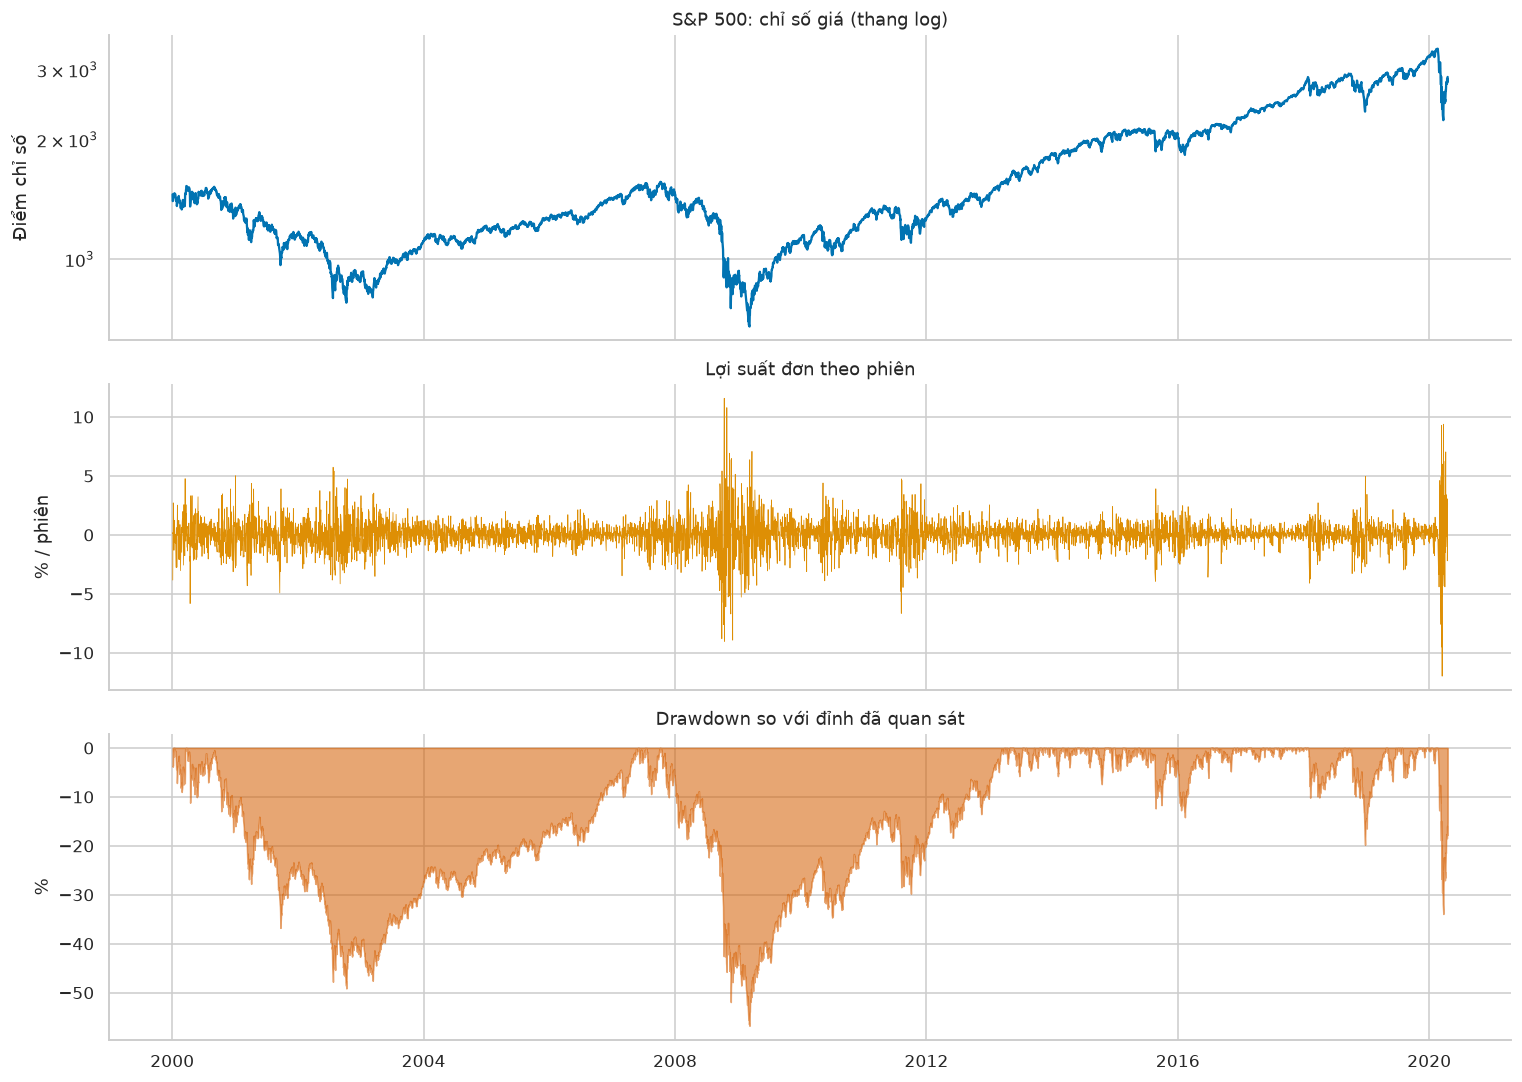

,Giá trị
Lợi suất giá toàn kỳ,97.53%
CAGR giá (theo số ngày lịch),3.41%
Độ lệch chuẩn lợi suất quy năm,19.89%
Drawdown lớn nhất,-56.78%
Tỷ lệ phiên tăng,53.51%
Phiên tệ nhất,-11.98%
Phiên tốt nhất,11.58%


,Đỉnh trước drawdown,Đáy,Mức sụt giảm,Phục hồi đỉnh cũ
0,2007-10-09,2009-03-09,-56.78%,2013-03-28


In [4]:
close = prices['close']
drawdown = close.div(close.cummax()).sub(1)
rv22 = returns.pow(2).rolling(22).mean().mul(ANNUAL).pow(.5)
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
axes[0].plot(close.index, close, color='C0'); axes[0].set_yscale('log')
axes[0].set(title='S&P 500: chỉ số giá (thang log)', ylabel='Điểm chỉ số')
axes[1].plot(returns.index, returns * 100, lw=.5, color='C1')
axes[1].set(title='Lợi suất đơn theo phiên', ylabel='% / phiên')
axes[2].fill_between(drawdown.index, drawdown * 100, 0, color='C3', alpha=.55)
axes[2].set(title='Drawdown so với đỉnh đã quan sát', ylabel='%')
plt.tight_layout(); plt.show()

years = (close.index[-1] - close.index[0]).days / 365.25
market_summary = pd.Series({
    'Lợi suất giá toàn kỳ': close.iloc[-1] / close.iloc[0] - 1,
    'CAGR giá (theo số ngày lịch)': (close.iloc[-1] / close.iloc[0]) ** (1 / years) - 1,
    'Độ lệch chuẩn lợi suất quy năm': returns.std() * np.sqrt(ANNUAL),
    'Drawdown lớn nhất': drawdown.min(),
    'Tỷ lệ phiên tăng': (returns.dropna() > 0).mean(),
    'Phiên tệ nhất': returns.min(), 'Phiên tốt nhất': returns.max(),
}, name='Giá trị')
display(market_summary.to_frame().style.format('{:.2%}'))
trough = drawdown.idxmin(); peak = close.loc[:trough].idxmax()
recovery = close.loc[trough:][close.loc[trough:] >= close.loc[peak]]
recovery_date = str(recovery.index[0].date()) if len(recovery) else 'Chưa phục hồi trong dữ liệu'
display(pd.DataFrame({'Đỉnh trước drawdown': [peak.date()], 'Đáy': [trough.date()],
                      'Mức sụt giảm': [f'{drawdown.min():.2%}'], 'Phục hồi đỉnh cũ': [recovery_date]}))

### 2.2. Lợi suất theo năm và tháng: mức sinh lời có ổn định không?

Lợi suất được **ghép lãi**, không cộng phần trăm. Năm đầu/cuối có thể không đủ 12 tháng. Mỗi ô tháng chỉ mô tả quá khứ, chưa phải bằng chứng rằng mùa vụ sẽ lặp lại.

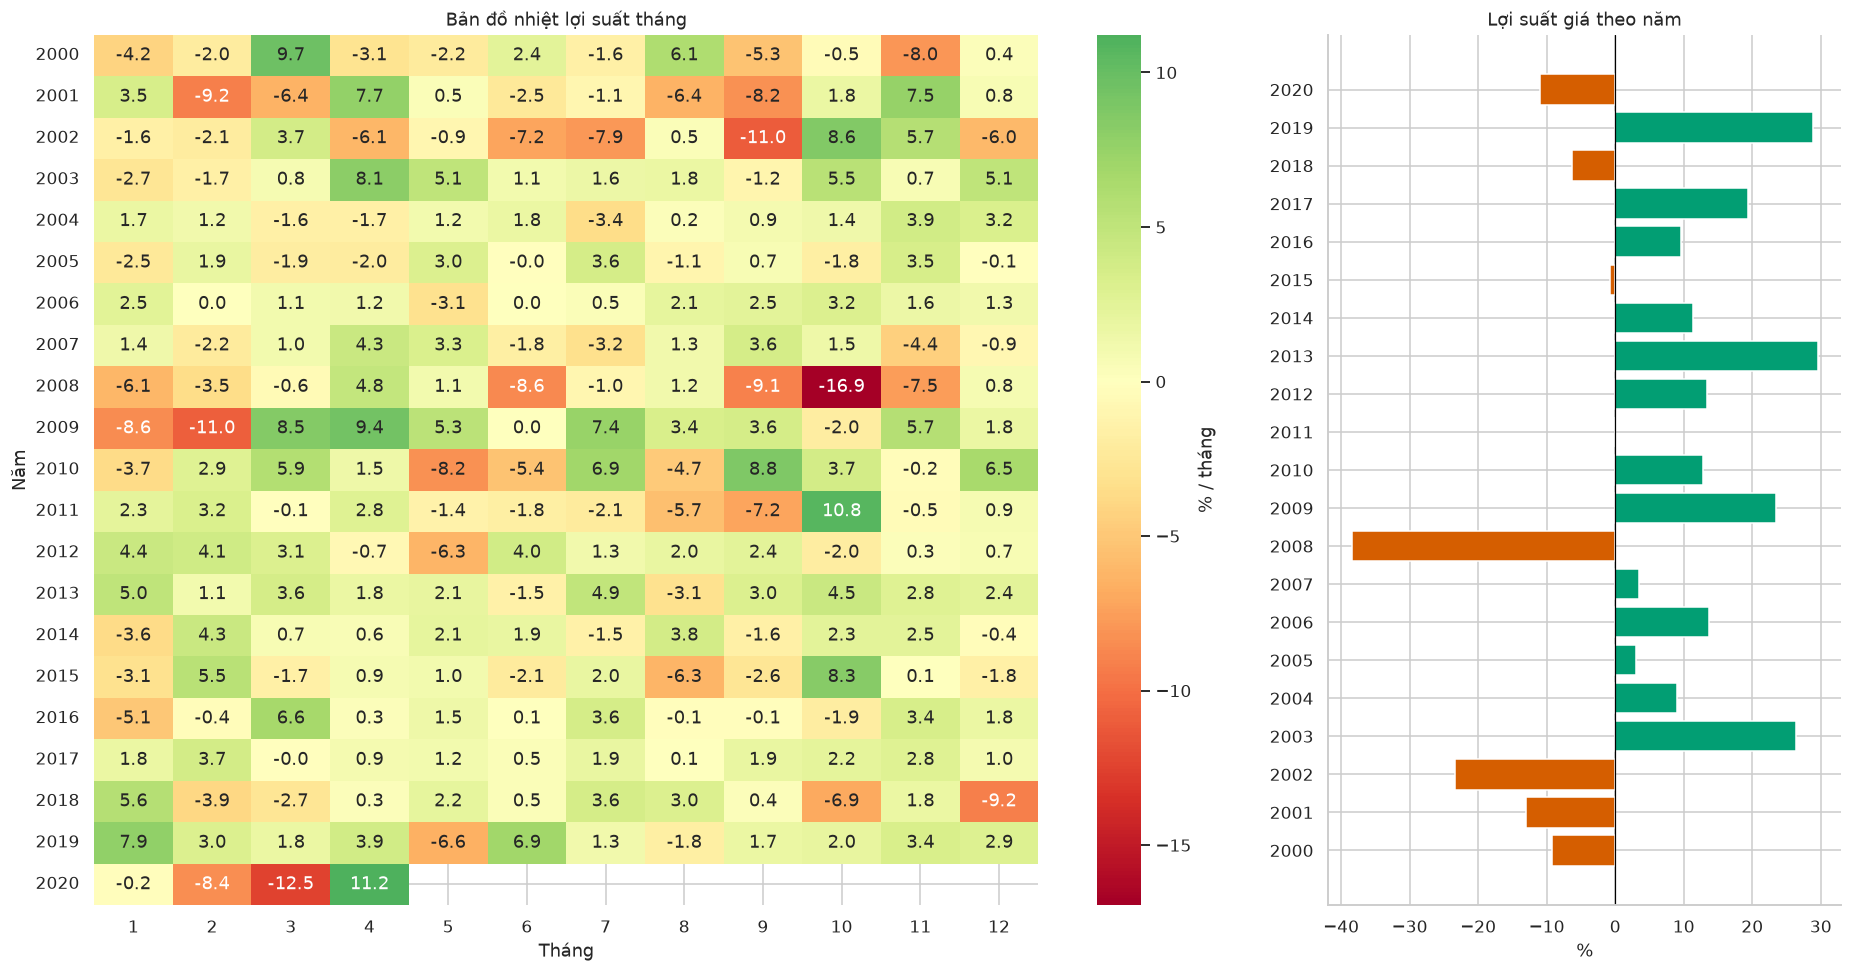

,Lợi suất ghép,Độ lệch chuẩn quy năm,Số phiên có lợi suất,RV22 cao nhất
date,,,,
2000,-9.3%,22.2%,251,33.2%
2001,-13.0%,21.6%,248,35.1%
2002,-23.4%,26.0%,252,45.5%
2003,26.4%,17.1%,252,28.1%
2004,9.0%,11.1%,252,15.1%
2005,3.0%,10.3%,252,15.4%
2006,13.6%,10.0%,251,15.7%
2007,3.5%,16.0%,251,25.7%
2008,-38.5%,41.0%,253,88.1%


In [5]:
monthly_returns = (1 + returns.dropna()).resample('ME').prod() - 1
heatmap_data = monthly_returns.to_frame('return')
heatmap_data['year'] = heatmap_data.index.year
heatmap_data['month'] = heatmap_data.index.month
pivot = heatmap_data.pivot(index='year', columns='month', values='return').reindex(columns=range(1, 13))
yearly = pd.DataFrame({
    'Lợi suất ghép': (1 + returns.dropna()).resample('YE').prod() - 1,
    'Độ lệch chuẩn quy năm': returns.resample('YE').std() * np.sqrt(ANNUAL),
    'Số phiên có lợi suất': returns.resample('YE').count(),
    'RV22 cao nhất': rv22.resample('YE').max(),
})
yearly.index = yearly.index.year
fig, axes = plt.subplots(1, 2, figsize=(17, 9), gridspec_kw={'width_ratios': [2.3, 1]})
sns.heatmap(pivot * 100, cmap='RdYlGn', center=0, annot=True, fmt='.1f', ax=axes[0], cbar_kws={'label': '% / tháng'})
axes[0].set(title='Bản đồ nhiệt lợi suất tháng', xlabel='Tháng', ylabel='Năm')
axes[1].barh(yearly.index.astype(str), yearly['Lợi suất ghép'] * 100,
             color=np.where(yearly['Lợi suất ghép'] >= 0, 'C2', 'C3'))
axes[1].axvline(0, color='black', lw=.8); axes[1].set(title='Lợi suất giá theo năm', xlabel='%')
plt.tight_layout(); plt.show()
display(yearly.style.format({'Lợi suất ghép': '{:.1%}', 'Độ lệch chuẩn quy năm': '{:.1%}', 'RV22 cao nhất': '{:.1%}'}))

### 2.3. Đuôi phân phối, ngoại lệ và cụm biến động

Phân phối chuẩn là đường tham chiếu, không phải giả định đúng. Nếu hai đuôi Q–Q lệch mạnh, mô hình dùng phân phối chuẩn có thể đánh giá thấp xác suất biến động cực đoan. Excess kurtosis bằng 0 đối với phân phối chuẩn.

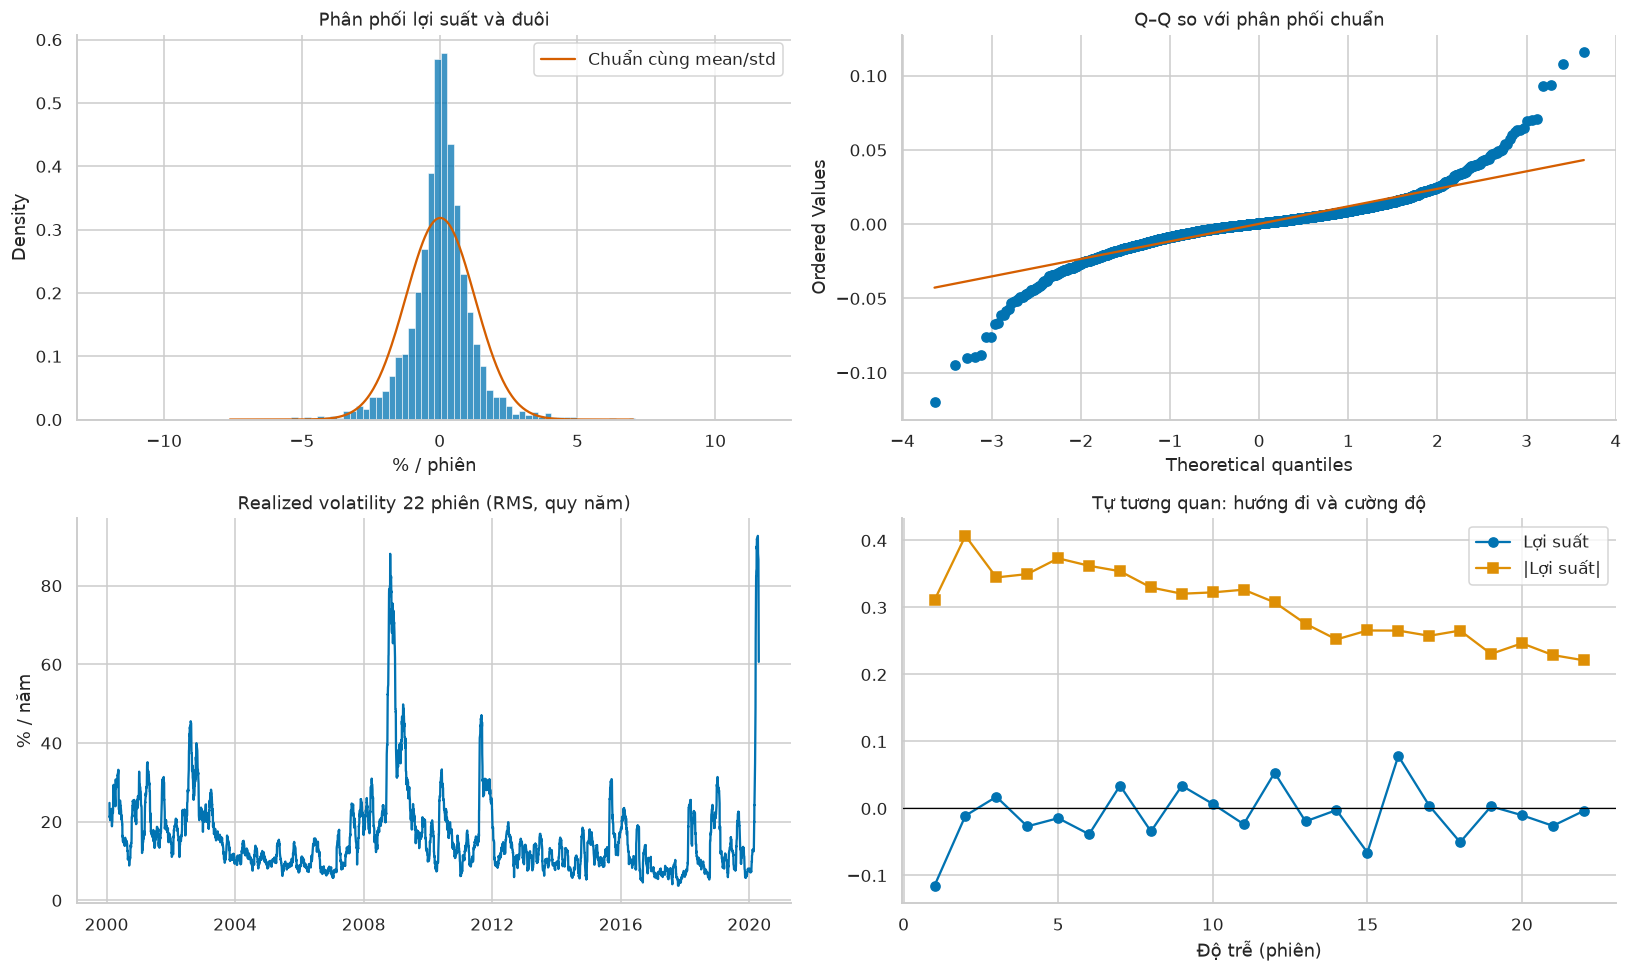

,Giá trị
Skewness,-0.1227
Excess kurtosis,11.0291
Quantile 1%,-0.0345
Quantile 5%,-0.0189
Quantile 95%,0.0172
Quantile 99%,0.0359
ACF lợi suất lag 1,-0.1152
ACF |lợi suất| lag 1,0.3110


,Lợi suất
date,
2020-03-16 00:00:00,-11.98%
2020-03-12 00:00:00,-9.51%
2008-10-15 00:00:00,-9.03%
2008-12-01 00:00:00,-8.93%
2008-09-29 00:00:00,-8.81%
2009-03-23 00:00:00,7.08%
2020-03-13 00:00:00,9.29%
2020-03-24 00:00:00,9.38%
2008-10-28 00:00:00,10.79%


**Đọc từ dữ liệu:** ACF lag 1 của lợi suất = **-0.115**, của độ lớn lợi suất = **0.311**. Sự khác biệt gợi ý kiểm tra tính dai dẳng của rủi ro; chưa chứng minh khả năng dự báo ngoài mẫu.

In [6]:
r = returns.dropna()
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
x = np.linspace(r.quantile(.001), r.quantile(.999), 400)
sns.histplot(r * 100, bins=100, stat='density', ax=axes[0, 0], color='C0')
axes[0, 0].plot(x * 100, stats.norm.pdf(x, r.mean(), r.std()) / 100, color='C3', label='Chuẩn cùng mean/std')
axes[0, 0].set(title='Phân phối lợi suất và đuôi', xlabel='% / phiên'); axes[0, 0].legend()
stats.probplot(r, dist='norm', plot=axes[0, 1]); axes[0, 1].set_title('Q–Q so với phân phối chuẩn')
axes[1, 0].plot(rv22.index, rv22 * 100); axes[1, 0].set(title='Realized volatility 22 phiên (RMS, quy năm)', ylabel='% / năm')
lags = range(1, 23)
axes[1, 1].plot(lags, [r.autocorr(k) for k in lags], marker='o', label='Lợi suất')
axes[1, 1].plot(lags, [r.abs().autocorr(k) for k in lags], marker='s', label='|Lợi suất|')
axes[1, 1].axhline(0, color='black', lw=.8); axes[1, 1].set(title='Tự tương quan: hướng đi và cường độ', xlabel='Độ trễ (phiên)')
axes[1, 1].legend(); plt.tight_layout(); plt.show()
tail_stats = pd.Series({'Skewness': r.skew(), 'Excess kurtosis': r.kurt(),
    'Quantile 1%': r.quantile(.01), 'Quantile 5%': r.quantile(.05),
    'Quantile 95%': r.quantile(.95), 'Quantile 99%': r.quantile(.99),
    'ACF lợi suất lag 1': r.autocorr(1), 'ACF |lợi suất| lag 1': r.abs().autocorr(1)}, name='Giá trị')
display(tail_stats.to_frame().round(4))
extremes = pd.concat([r.nsmallest(5), r.nlargest(5)]).sort_values().to_frame('Lợi suất')
display(extremes.style.format({'Lợi suất': '{:.2%}'}))
display(Markdown(f'**Đọc từ dữ liệu:** ACF lag 1 của lợi suất = **{r.autocorr(1):.3f}**, '
    f'của độ lớn lợi suất = **{r.abs().autocorr(1):.3f}**. '
    'Sự khác biệt gợi ý kiểm tra tính dai dẳng của rủi ro; chưa chứng minh khả năng dự báo ngoài mẫu.'))

### 2.4. Ngày trong tuần: mô tả cùng cỡ mẫu và độ bất định

Các thanh sai số là khoảng xấp xỉ 95% cho trung bình (giả định phiên độc lập). Vì thị trường có phụ thuộc thời gian, đây chỉ là mô tả ban đầu; không dùng biểu đồ này để tuyên bố chiến lược có lợi nhuận. Quan sát nhiều nhóm cùng lúc cũng làm tăng nguy cơ tìm thấy “quy luật” ngẫu nhiên.

/tmp/ipykernel_2284/4108975229.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  weekday['weekday'] = weekday.index.dayofweek


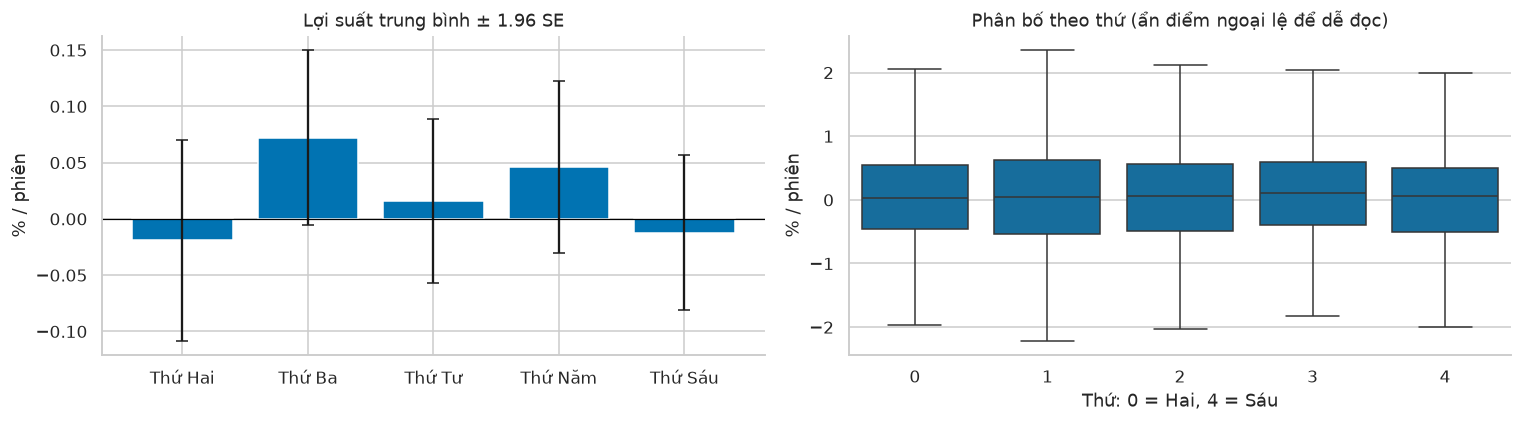

,count,mean,std,SE
Thứ Hai,958,-0.00019,0.01409,0.00046
Thứ Ba,1045,0.00072,0.01278,0.00040
Thứ Tư,1047,0.00016,0.01202,0.00037
Thứ Năm,1029,0.00046,0.01245,0.00039
Thứ Sáu,1025,-0.00012,0.01124,0.00035


In [7]:
weekday = r.to_frame('return')
weekday['weekday'] = weekday.index.dayofweek
weekday_summary = weekday.groupby('weekday')['return'].agg(['count', 'mean', 'std'])
weekday_summary['SE'] = weekday_summary['std'] / np.sqrt(weekday_summary['count'])
weekday_summary.index = ['Thứ Hai', 'Thứ Ba', 'Thứ Tư', 'Thứ Năm', 'Thứ Sáu'][:len(weekday_summary)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(weekday_summary.index, weekday_summary['mean'] * 100,
            yerr=1.96 * weekday_summary['SE'] * 100, capsize=4)
axes[0].axhline(0, color='black', lw=.8); axes[0].set(title='Lợi suất trung bình ± 1.96 SE', ylabel='% / phiên')
sns.boxplot(x=weekday['weekday'], y=weekday['return'] * 100, showfliers=False, ax=axes[1])
axes[1].set(title='Phân bố theo thứ (ẩn điểm ngoại lệ để dễ đọc)', xlabel='Thứ: 0 = Hai, 4 = Sáu', ylabel='% / phiên')
plt.tight_layout(); plt.show()
display(weekday_summary.round(5))

## 3. Mục tiêu, đặc trưng và ranh giới thông tin

### 3.1. Dự báo rủi ro trong 5 phiên thực sự ở tương lai

Với lợi suất đơn $r_t=P_t/P_{t-1}-1$, mục tiêu là:

$$RV_{t+1:t+H}=\sqrt{\frac{252}{H}\sum_{j=1}^{H} r_{t+j}^2},\quad H=5.$$

Đây là **RMS của lợi suất quy năm**, không phải độ lệch chuẩn đã trừ trung bình. Mục tiêu này dùng thông tin từ *t+1* đến *t+5*, nên H dòng cuối phải thiếu nhãn. Các nhãn liên tiếp vẫn chồng lấn nhau; điều đó cần được phản ánh khi chia tập và tính độ bất định.

Đặc trưng chỉ dùng dữ liệu đến hết *t*: lợi suất và độ lớn lợi suất, RV 5/10/22/66 phiên, EWMA, momentum, RSI, khoảng cách tới MA và drawdown 252 phiên. Chỉ dùng biên độ High–Low khi dữ liệu OHLC có thật. Không dùng Volume của chỉ số làm đại diện cho lượng giao dịch cổ phiếu.

**Giả thuyết:** độ lớn và tính dai dẳng của biến động có thể hữu ích cho dự báo rủi ro, trong khi hướng tăng/giảm có thể khó dự báo hơn nhiều.

In [8]:
def build_features(frame, horizon=5):
    c = frame['close']
    ret = c.pct_change(fill_method=None)
    X = pd.DataFrame(index=frame.index)
    X['return_1'] = ret
    X['abs_return_1'] = ret.abs()
    X['negative_return_1'] = ret.clip(upper=0)
    for window in [5, 10, 22, 66]:
        X[f'rv_{window}'] = ret.pow(2).rolling(window).mean().mul(ANNUAL).pow(.5)
    X['ewma_94'] = ret.pow(2).ewm(alpha=.06, adjust=False, min_periods=22).mean().mul(ANNUAL).pow(.5)
    for window in [5, 22, 66]:
        X[f'momentum_{window}'] = c.pct_change(window, fill_method=None)
    X['distance_ma22'] = c / c.rolling(22).mean() - 1
    X['drawdown_252'] = c / c.rolling(252, min_periods=66).max() - 1
    gain = ret.clip(lower=0).rolling(14).mean()
    loss = (-ret.clip(upper=0)).rolling(14).mean()
    X['rsi_14'] = 100 * gain / (gain + loss).replace(0, np.nan)
    X['rv_short_long'] = X['rv_5'] / X['rv_22']
    if {'high', 'low'}.issubset(frame.columns):
        X['range_1'] = np.log(frame['high'] / frame['low'])
        X['range_mean_5'] = X['range_1'].rolling(5).mean()
    future_rv = ret.pow(2).rolling(horizon).mean().shift(-horizon).mul(ANNUAL).pow(.5)
    next_ret = ret.shift(-1)
    direction = (next_ret > 0).astype(float).where(next_ret.notna())
    return X.replace([np.inf, -np.inf], np.nan), future_rv.rename('future_rv'), direction.rename('up_next')

X_all, y_all, y_direction_all = build_features(prices, H)
valid = X_all.notna().all(axis=1) & y_all.notna() & (y_all > 0) & y_direction_all.notna()
X = X_all.loc[valid].copy()
y = y_all.loc[valid].copy()
y_direction = y_direction_all.loc[valid].astype(int)
label_end = pd.Series(prices.index, index=prices.index).shift(-H).loc[X.index]

# Kiểm tra ý nghĩa nhãn và việc giữ thiếu ở biên tương lai.
assert y_all.iloc[-H:].isna().all()
assert pd.isna(y_direction_all.iloc[-1])
check_date = X.index[100]
pos = prices.index.get_loc(check_date)
expected = np.sqrt(ANNUAL * returns.iloc[pos+1:pos+H+1].pow(2).mean())
assert np.isclose(y.loc[check_date], expected)
# Thay giá tương lai không được làm thay đổi đặc trưng quá khứ.
cutoff = len(prices) // 2
changed = prices.copy()
changed.loc[changed.index[cutoff+1]:, 'close'] *= 1.1
changed_features, _, _ = build_features(changed, H)
pd.testing.assert_frame_equal(X_all.iloc[:cutoff+1], changed_features.iloc[:cutoff+1])
print(f'{len(X):,} mẫu có nhãn; {X.shape[1]} đặc trưng; kiểm tra nhãn và tính nhân quả: PASS.')
display(X.join(y).head().round(4))

5,034 mẫu có nhãn; 17 đặc trưng; kiểm tra nhãn và tính nhân quả: PASS.


,return_1,abs_return_1,negative_return_1,rv_5,rv_10,rv_22,rv_66,...,distance_ma22,drawdown_252,rsi_14,rv_short_long,range_1,range_mean_5,future_rv
date,,,,,,,,,,,,,,,
2000-04-06,0.0094,0.0094,0.0000,0.1109,0.1175,0.2526,0.2392,...,0.0244,-0.0171,61.2152,0.4389,0.0163,0.0295,0.2239
2000-04-07,0.0100,0.0100,0.0000,0.1214,0.1278,0.2533,0.2280,...,0.0298,-0.0073,67.2294,0.4793,0.0115,0.0270,0.4650
2000-04-10,-0.0078,0.0078,-0.0078,0.1289,0.1332,0.2395,0.2285,...,0.0185,-0.0151,53.7468,0.5381,0.0157,0.0275,0.5180
2000-04-11,-0.0026,0.0026,-0.0026,0.1189,0.1228,0.2391,0.2285,...,0.0126,-0.0176,50.2428,0.4972,0.0173,0.0160,0.5562
2000-04-12,-0.0223,0.0223,-0.0223,0.1947,0.1661,0.2492,0.2265,...,-0.0125,-0.0395,30.9217,0.7814,0.0289,0.0179,0.5378


,Tập,Từ,Đến,Số mẫu,Nhãn cuối dùng đến
0,Train,2000-04-06,2014-04-02,3518,2014-04-09
1,Validation,2014-04-10,2017-03-31,750,2017-04-07
2,Test khóa,2017-04-10,2020-04-09,756,2020-04-17


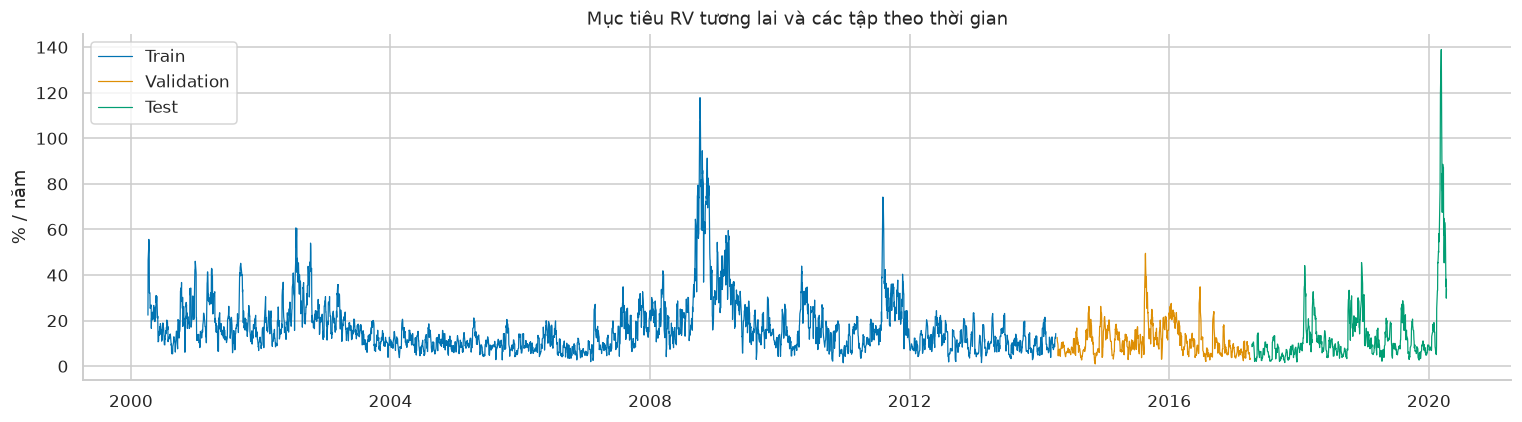

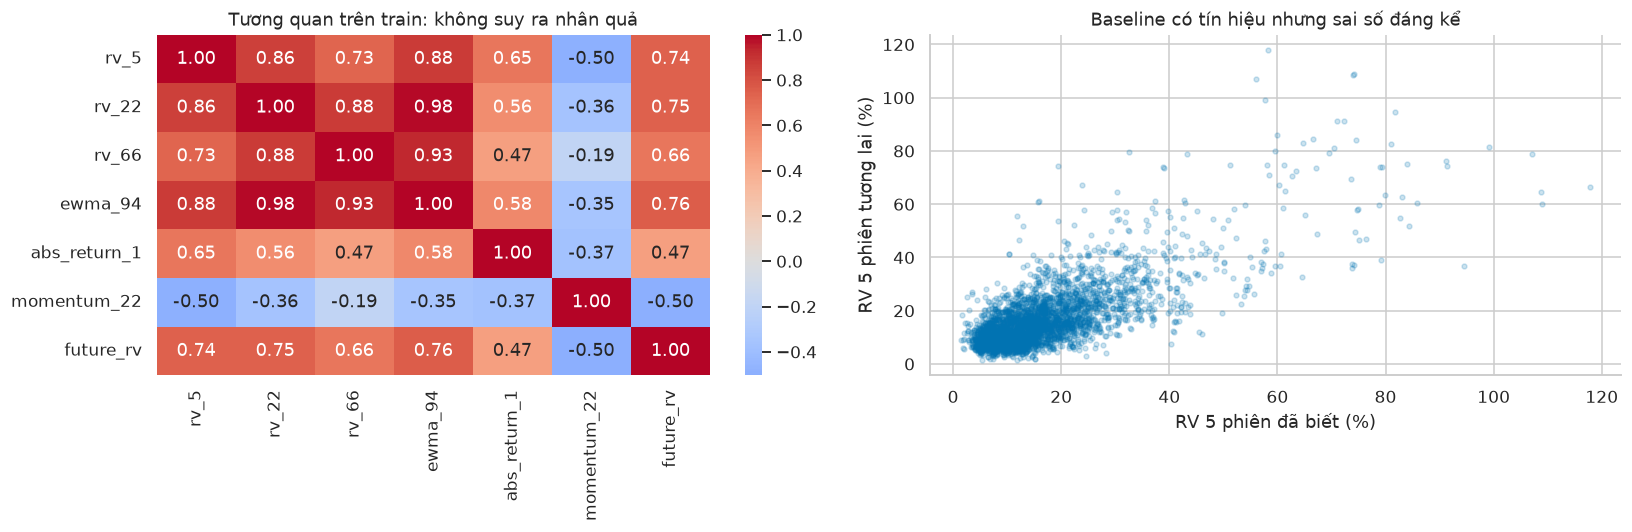

In [9]:
# 70% train, 15% validation, 15% test; bỏ H hàng trước mỗi ranh giới.
n = len(X)
a, b = int(n * .70), int(n * .85)
train_idx = np.arange(0, a-H)
val_idx = np.arange(a, b-H)
test_idx = np.arange(b, n)
dev_idx = np.arange(0, b-H)  # refit sau khi đóng băng lựa chọn; giữ gap trước test
assert label_end.iloc[train_idx].max() < X.index[val_idx[0]]
assert label_end.iloc[val_idx].max() < X.index[test_idx[0]]
assert label_end.iloc[dev_idx].max() < X.index[test_idx[0]]
assert set(train_idx).isdisjoint(val_idx) and set(val_idx).isdisjoint(test_idx)

split_table = pd.DataFrame([
    {'Tập': name, 'Từ': X.index[idx[0]].date(), 'Đến': X.index[idx[-1]].date(),
     'Số mẫu': len(idx), 'Nhãn cuối dùng đến': label_end.iloc[idx].max().date()}
    for name, idx in [('Train', train_idx), ('Validation', val_idx), ('Test khóa', test_idx)]
])
display(split_table)
fig, ax = plt.subplots(figsize=(14, 4))
for name, idx, color in [('Train', train_idx, 'C0'), ('Validation', val_idx, 'C1'), ('Test', test_idx, 'C2')]:
    ax.plot(y.index[idx], y.iloc[idx] * 100, color=color, label=name, lw=.8)
ax.set(title='Mục tiêu RV tương lai và các tập theo thời gian', ylabel='% / năm')
ax.legend(); plt.tight_layout(); plt.show()

# Tương quan chỉ tính trên TRAIN; tránh nhìn test để chọn đặc trưng.
corr_columns = ['rv_5', 'rv_22', 'rv_66', 'ewma_94', 'abs_return_1', 'momentum_22']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(X.iloc[train_idx][corr_columns].join(y.iloc[train_idx]).corr(),
            annot=True, fmt='.2f', center=0, cmap='coolwarm', ax=axes[0])
axes[0].set_title('Tương quan trên train: không suy ra nhân quả')
axes[1].scatter(X.iloc[train_idx]['rv_5'] * 100, y.iloc[train_idx] * 100, alpha=.2, s=10)
axes[1].set(xlabel='RV 5 phiên đã biết (%)', ylabel='RV 5 phiên tương lai (%)', title='Baseline có tín hiệu nhưng sai số đáng kể')
plt.tight_layout(); plt.show()

## 4. Mô hình và thước đo: thắng baseline mới có ý nghĩa

**Baseline:** (1) RV 5 phiên vừa qua; (2) RV 22 phiên; (3) EWMA của bình phương lợi suất với λ = 0.94. Hằng số 0.94 được cố định trước, không chọn theo test.

**Mô hình học:** HAR dạng log-Ridge từ các cửa sổ rủi ro 5/22/66 phiên; Ridge dùng tất cả đặc trưng; HistGradientBoosting và ExtraTrees với độ phức tạp hạn chế; PyTorch MLP nhỏ có early stopping. Đây là danh sách ứng viên có chủ đích, không tìm kiếm hàng trăm cấu hình.

Mô hình học `log(RV)` để đầu ra luôn dương. Hàm mũ của dự báo log không tự động là kỳ vọng có điều kiện của RV; vì thế vẫn phải đánh giá bằng nhiều thước đo trên thang gốc.

| Thước đo | Cách đọc |
|---|---|
| RMSE / MAE | Thấp hơn tốt hơn; đơn vị gốc là biến động quy năm, không phải % accuracy |
| R² | Có thể âm; không diễn giải thành tỷ lệ dự báo đúng |
| QLIKE | Trung bình `z − log(z) − 1`, với `z = RV_thực² / RV_dự_báo²`; thấp hơn tốt hơn |
| RMSE skill | `1 − RMSE_model/RMSE_baseline`; âm nghĩa là thua baseline |

Chọn mô hình theo **QLIKE trên validation**, đồng thời báo cáo RMSE/MAE để nhìn trade-off. Không tối ưu theo test. PyTorch dùng CPU, seed cố định và một đoạn cuối của train cho early stopping; scaler chỉ fit trên phần train nội bộ.

In [10]:
class FeatureBaseline(RegressorMixin, BaseEstimator):
    def __init__(self, column='rv_5'):
        self.column = column
    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        return self
    def predict(self, X):
        return X[self.column].to_numpy().clip(1e-6)


class HARLogRidge(RegressorMixin, BaseEstimator):
    def __init__(self, alpha=10.):
        self.alpha = alpha
    def fit(self, X, y):
        self.columns_ = ['rv_5', 'rv_22', 'rv_66']
        self.model_ = make_pipeline(StandardScaler(), Ridge(alpha=self.alpha))
        self.model_.fit(np.log(X[self.columns_].clip(lower=1e-6)), np.log(y))
        return self
    def predict(self, X):
        return np.exp(self.model_.predict(np.log(X[self.columns_].clip(lower=1e-6))))


class TorchMLPRegressor(RegressorMixin, BaseEstimator):
    """Nhận log-target qua TransformedTargetRegressor; validation nội bộ theo thời gian."""
    def __init__(self, epochs=150, patience=15, learning_rate=.001, seed=SEED):
        self.epochs = epochs
        self.patience = patience
        self.learning_rate = learning_rate
        self.seed = seed
    def fit(self, X, y):
        torch.manual_seed(self.seed)
        raw_x = np.asarray(X, dtype=np.float32)
        raw_y = np.asarray(y).reshape(-1, 1)
        boundary = int(len(raw_x) * .85)
        core_end = boundary-H
        self.x_scaler_ = StandardScaler().fit(raw_x[:core_end])
        self.y_scaler_ = StandardScaler().fit(raw_y[:core_end])
        xt = torch.tensor(self.x_scaler_.transform(raw_x[:core_end]), dtype=torch.float32)
        yt = torch.tensor(self.y_scaler_.transform(raw_y[:core_end]), dtype=torch.float32)
        xv = torch.tensor(self.x_scaler_.transform(raw_x[boundary:]), dtype=torch.float32)
        yv = torch.tensor(self.y_scaler_.transform(raw_y[boundary:]), dtype=torch.float32)
        self.network_ = nn.Sequential(nn.Linear(raw_x.shape[1], 24), nn.ReLU(),
                                      nn.Linear(24, 12), nn.ReLU(), nn.Linear(12, 1))
        optimizer = torch.optim.AdamW(self.network_.parameters(), lr=self.learning_rate, weight_decay=.01)
        criterion = nn.MSELoss()
        best, stale, state = np.inf, 0, None
        self.history_ = []
        for epoch in range(self.epochs):
            self.network_.train()
            order = torch.randperm(len(xt))
            for batch in order.split(128):
                optimizer.zero_grad()
                loss = criterion(self.network_(xt[batch]), yt[batch])
                loss.backward()
                optimizer.step()
            self.network_.eval()
            with torch.no_grad():
                train_loss = criterion(self.network_(xt), yt).item()
                val_loss = criterion(self.network_(xv), yv).item()
            self.history_.append((train_loss, val_loss))
            if val_loss < best - 1e-5:
                best, stale = val_loss, 0
                state = copy.deepcopy(self.network_.state_dict())
            else:
                stale += 1
            if stale >= self.patience:
                break
        self.network_.load_state_dict(state)
        self.network_.eval()
        self.best_internal_loss_ = best
        return self
    def predict(self, X):
        xt = torch.tensor(self.x_scaler_.transform(np.asarray(X)), dtype=torch.float32)
        with torch.no_grad():
            standardized = self.network_(xt).numpy()
        return self.y_scaler_.inverse_transform(standardized).ravel()


def log_target(regressor):
    return TransformedTargetRegressor(regressor=regressor, func=np.log, inverse_func=np.exp)


def qlike(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    if not np.isfinite(predicted).all() or (predicted <= 0).any():
        raise ValueError('Dự báo biến động phải hữu hạn và dương.')
    ratio = (actual / predicted) ** 2
    return np.mean(ratio - np.log(ratio) - 1)


def regression_metrics(actual, predicted):
    return {'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
            'MAE': mean_absolute_error(actual, predicted),
            'R2': r2_score(actual, predicted), 'QLIKE': qlike(actual, predicted)}


candidates = {
    'Baseline RV5': FeatureBaseline('rv_5'),
    'Baseline RV22': FeatureBaseline('rv_22'),
    'Baseline EWMA': FeatureBaseline('ewma_94'),
    'HAR log-Ridge': HARLogRidge(alpha=10.),
    'Ridge log': log_target(make_pipeline(StandardScaler(), Ridge(alpha=30.))),
    'HistGB log': log_target(HistGradientBoostingRegressor(max_iter=150,
        max_leaf_nodes=7, min_samples_leaf=50, learning_rate=.04,
        l2_regularization=10., early_stopping=False, random_state=SEED)),
    'ExtraTrees log': log_target(ExtraTreesRegressor(n_estimators=150, max_depth=8,
        min_samples_leaf=25, max_features=.8, n_jobs=2, random_state=SEED)),
}
if RUN_MLP:
    candidates['PyTorch MLP log'] = log_target(TorchMLPRegressor())

val_rows, val_predictions, val_fitted = [], {}, {}
for name, estimator in candidates.items():
    started = time.perf_counter()
    fitted = clone(estimator).fit(X.iloc[train_idx], y.iloc[train_idx])
    prediction = fitted.predict(X.iloc[val_idx])
    val_predictions[name] = prediction
    val_fitted[name] = fitted
    val_rows.append({'Model': name, **regression_metrics(y.iloc[val_idx], prediction),
                     'Fit + predict (s)': time.perf_counter() - started})
    print(f'Validation xong: {name}')
validation_results = pd.DataFrame(val_rows).set_index('Model').sort_values('QLIKE')
selected_name = validation_results.index[0]  # đóng băng trước khi mở test
baseline_names = [name for name in candidates if name.startswith('Baseline')]
selected_baseline = validation_results.loc[baseline_names, 'QLIKE'].idxmin()
validation_results['RMSE skill vs RV5'] = 1 - validation_results['RMSE'] / validation_results.loc['Baseline RV5', 'RMSE']
display(validation_results.round(4))
print('Lựa chọn đóng băng từ validation:', selected_name)
print('Baseline được chọn từ validation:', selected_baseline)

Validation xong: Baseline RV5
Validation xong: Baseline RV22
Validation xong: Baseline EWMA
Validation xong: HAR log-Ridge
Validation xong: Ridge log
Validation xong: HistGB log


Validation xong: ExtraTrees log


Validation xong: PyTorch MLP log


,RMSE,MAE,R2,QLIKE,Fit + predict (s),RMSE skill vs RV5
Model,,,,,,
Ridge log,0.0529,0.0376,0.3766,0.4287,0.0055,0.2293
HistGB log,0.0518,0.0361,0.4017,0.4341,0.0976,0.2449
ExtraTrees log,0.0523,0.0362,0.3899,0.4432,0.2092,0.2375
PyTorch MLP log,0.0519,0.0350,0.4000,0.4496,2.3495,0.2438
Baseline EWMA,0.0628,0.0455,0.1213,0.5921,0.0023,0.0850
HAR log-Ridge,0.0597,0.0415,0.2051,0.6512,0.0080,0.1297
Baseline RV22,0.0670,0.0472,-0.0000,0.7554,0.0019,0.0238
Baseline RV5,0.0686,0.0485,-0.0494,1.3401,0.0222,0.0000


Lựa chọn đóng băng từ validation: Ridge log
Baseline được chọn từ validation: Baseline EWMA


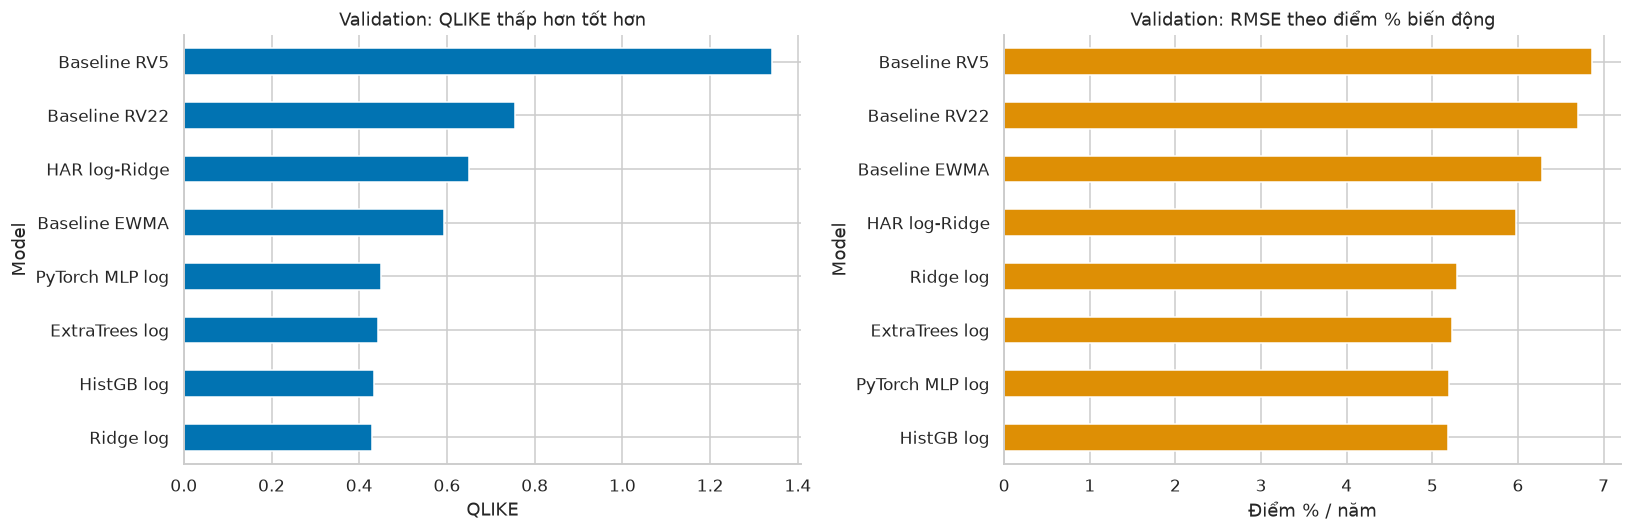

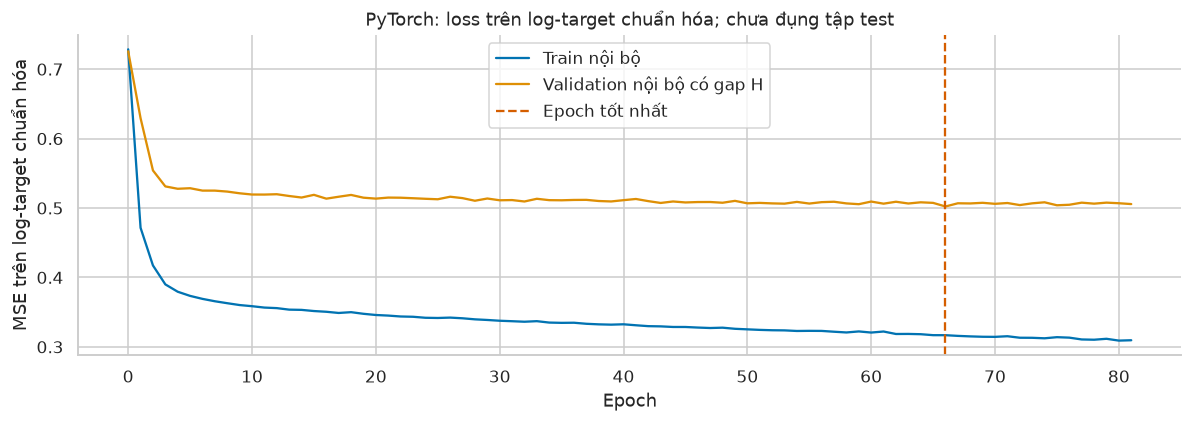

Không dùng đường loss nội bộ để tuyên bố dự báo tốt; so sánh validation bên ngoài ở bảng trên.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
validation_results['QLIKE'].sort_values().plot.barh(ax=axes[0], color='C0')
axes[0].set(title='Validation: QLIKE thấp hơn tốt hơn', xlabel='QLIKE')
validation_results['RMSE'].sort_values().mul(100).plot.barh(ax=axes[1], color='C1')
axes[1].set(title='Validation: RMSE theo điểm % biến động', xlabel='Điểm % / năm')
plt.tight_layout(); plt.show()
if RUN_MLP:
    history = np.asarray(val_fitted['PyTorch MLP log'].regressor_.history_)
    plt.figure(figsize=(11, 4))
    plt.plot(history[:, 0], label='Train nội bộ')
    plt.plot(history[:, 1], label='Validation nội bộ có gap H')
    plt.axvline(np.argmin(history[:, 1]), color='C3', ls='--', label='Epoch tốt nhất')
    plt.title('PyTorch: loss trên log-target chuẩn hóa; chưa đụng tập test')
    plt.xlabel('Epoch'); plt.ylabel('MSE trên log-target chuẩn hóa')
    plt.legend(); plt.tight_layout(); plt.show()
    print('Không dùng đường loss nội bộ để tuyên bố dự báo tốt; so sánh validation bên ngoài ở bảng trên.')

### 4.1. Độ ổn định qua các cửa sổ thời gian (chỉ trên train)

Một lần chia validation có thể ưu ái một chế độ thị trường. Kiểm tra mở rộng cửa sổ với ba fold và gap H giúp nhìn độ ổn định của mô hình đã chọn và baseline. Đây là chẩn đoán bổ sung, **không thay lựa chọn mô hình sau khi nhìn test**. Không shuffle các dòng dữ liệu trước khi chia fold.

,Fold,Model,Validation từ,Validation đến,RMSE,MAE,R2,QLIKE
0,1,Baseline EWMA,2003-10-10,2007-04-10,0.0377,0.0285,-0.0484,0.2997
1,1,HAR log-Ridge,2003-10-10,2007-04-10,0.0416,0.0334,-0.2761,0.3011
2,1,Ridge log,2003-10-10,2007-04-10,0.0399,0.0323,-0.1718,0.2675
3,2,Baseline EWMA,2007-04-11,2010-10-04,0.1086,0.0752,0.5774,0.3294
4,2,HAR log-Ridge,2007-04-11,2010-10-04,0.1152,0.0741,0.5245,0.4187
5,2,Ridge log,2007-04-11,2010-10-04,0.3664,0.1378,-3.8120,0.4831
6,3,Baseline EWMA,2010-10-05,2014-04-02,0.0704,0.0494,0.3334,0.4536
7,3,HAR log-Ridge,2010-10-05,2014-04-02,0.0678,0.0463,0.3832,0.4867
8,3,Ridge log,2010-10-05,2014-04-02,0.0642,0.0424,0.4468,0.3962


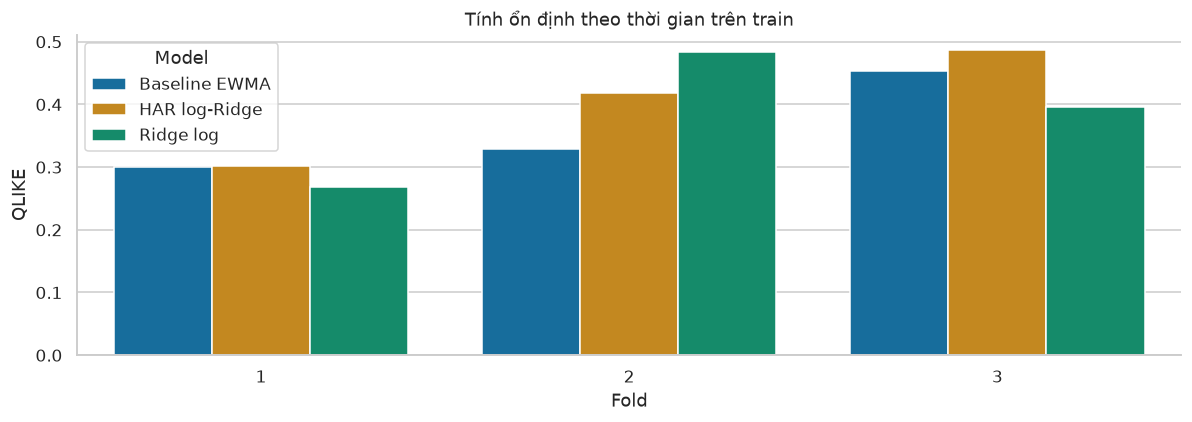

In [12]:
cv = TimeSeriesSplit(n_splits=3, gap=H)
cv_names = list(dict.fromkeys([selected_baseline, 'HAR log-Ridge', selected_name]))
cv_rows = []
train_X, train_y = X.iloc[train_idx], y.iloc[train_idx]
for fold, (tr, va) in enumerate(cv.split(train_X), 1):
    assert label_end.loc[train_X.index[tr]].max() < train_X.index[va[0]]
    for name in cv_names:
        fitted = clone(candidates[name]).fit(train_X.iloc[tr], train_y.iloc[tr])
        prediction = fitted.predict(train_X.iloc[va])
        cv_rows.append({'Fold': fold, 'Model': name,
            'Validation từ': str(train_X.index[va[0]].date()),
            'Validation đến': str(train_X.index[va[-1]].date()),
            **regression_metrics(train_y.iloc[va], prediction)})
cv_results = pd.DataFrame(cv_rows)
display(cv_results.round(4))
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=cv_results, x='Fold', y='QLIKE', hue='Model', ax=ax, errorbar=None)
ax.set_title('Tính ổn định theo thời gian trên train'); plt.tight_layout(); plt.show()

## 5. Kiểm thử cuối cùng: mở test sau khi đóng băng lựa chọn

Refit trên train + validation, giữ H phiên bị loại trước test. Chỉ mở test cho mô hình đã chọn và các baseline đã định trước. Nếu một baseline được chọn, notebook giữ nguyên lựa chọn đó thay vì ép mô hình phức tạp chiến thắng.

Không dùng bảng test để chỉnh lại mô hình trong notebook này. Nếu tiếp tục thử nghiệm sau khi xem test, cần một giai đoạn dữ liệu mới làm kiểm thử cuối cùng.

,RMSE,MAE,R2,QLIKE,RMSE skill vs chosen baseline,Đã chọn trước test
Model,,,,,,
Baseline RV5,0.1039,0.0611,0.5924,1.3260,0.0865,False
Baseline RV22,0.1234,0.0675,0.4243,0.8645,-0.0856,False
Baseline EWMA,0.1137,0.0633,0.5115,0.7869,0.0000,False
Ridge log,0.1182,0.0547,0.4725,0.7385,-0.0392,True


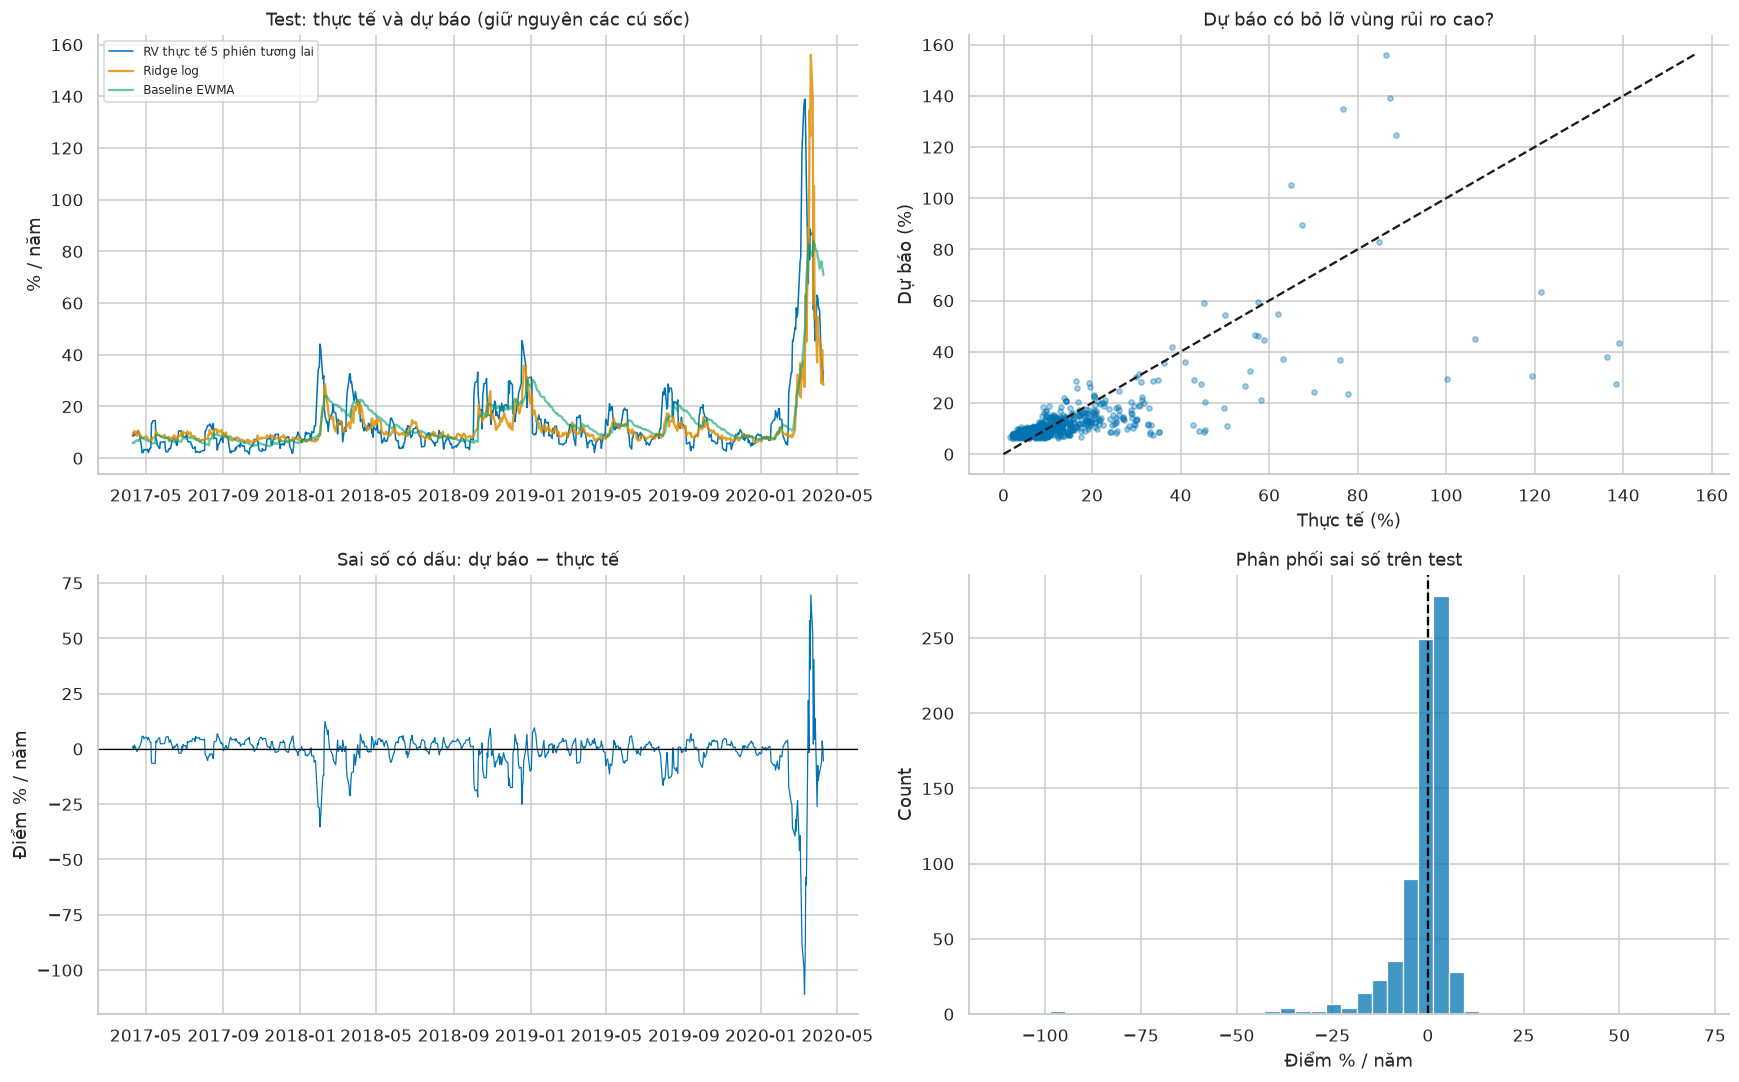

In [13]:
final_names = list(dict.fromkeys([*baseline_names, selected_name]))
final_models, test_predictions = {}, {}
for name in final_names:
    final_models[name] = clone(candidates[name]).fit(X.iloc[dev_idx], y.iloc[dev_idx])
    test_predictions[name] = final_models[name].predict(X.iloc[test_idx])
y_test = y.iloc[test_idx]
test_results = pd.DataFrame([
    {'Model': name, **regression_metrics(y_test, prediction)}
    for name, prediction in test_predictions.items()
]).set_index('Model')
ref_rmse = test_results.loc[selected_baseline, 'RMSE']
test_results['RMSE skill vs chosen baseline'] = 1 - test_results['RMSE'] / ref_rmse
test_results['Đã chọn trước test'] = test_results.index == selected_name
display(test_results.round(4))
selected_prediction = pd.Series(test_predictions[selected_name], index=y_test.index, name='predicted_rv')
reference_prediction = pd.Series(test_predictions[selected_baseline], index=y_test.index)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes[0, 0].plot(y_test.index, y_test * 100, label='RV thực tế 5 phiên tương lai', lw=1)
axes[0, 0].plot(y_test.index, selected_prediction * 100, label=selected_name, alpha=.85)
if selected_name != selected_baseline:
    axes[0, 0].plot(y_test.index, reference_prediction * 100, label=selected_baseline, alpha=.6)
axes[0, 0].set(title='Test: thực tế và dự báo (giữ nguyên các cú sốc)', ylabel='% / năm')
axes[0, 0].legend(fontsize=8)
axes[0, 1].scatter(y_test * 100, selected_prediction * 100, alpha=.35, s=12)
limit = max(y_test.max(), selected_prediction.max()) * 100
axes[0, 1].plot([0, limit], [0, limit], 'k--')
axes[0, 1].set(title='Dự báo có bỏ lỡ vùng rủi ro cao?', xlabel='Thực tế (%)', ylabel='Dự báo (%)')
residual = selected_prediction - y_test
axes[1, 0].plot(y_test.index, residual * 100, lw=.8)
axes[1, 0].axhline(0, color='black', lw=.8)
axes[1, 0].set(title='Sai số có dấu: dự báo − thực tế', ylabel='Điểm % / năm')
sns.histplot(residual * 100, bins=45, ax=axes[1, 1])
axes[1, 1].axvline(0, color='black', ls='--')
axes[1, 1].set(title='Phân phối sai số trên test', xlabel='Điểm % / năm')
plt.tight_layout(); plt.show()

### 5.1. Đánh giá theo chế độ rủi ro và giai đoạn

Ngưỡng thấp/vừa/cao lấy từ các tercile RV22 trên **train**, rồi áp vào RV22 đã biết tại thời điểm dự báo của test. Phân nhóm này không dùng biến động tương lai để tự định nghĩa chế độ.

Báo cáo theo năm và chế độ giúp tránh kết luận chỉ dựa vào một con số trung bình. Không loại giai đoạn khủng hoảng vì mô hình dự báo kém ở đó.

,Chế độ RV22,Model,Số phiên,RMSE,MAE,R2,QLIKE
0,Thấp,Baseline EWMA,463,0.0571,0.0381,0.0022,0.8265
1,Thấp,Ridge log,463,0.0523,0.0348,0.1627,0.6246
2,Vừa,Baseline EWMA,125,0.0922,0.0715,0.0430,0.8236
3,Vừa,Ridge log,125,0.0889,0.0510,0.1107,1.0505
4,Cao,Baseline EWMA,168,0.2070,0.1265,0.4151,0.6508
5,Cao,Ridge log,168,0.2222,0.1123,0.3257,0.8200


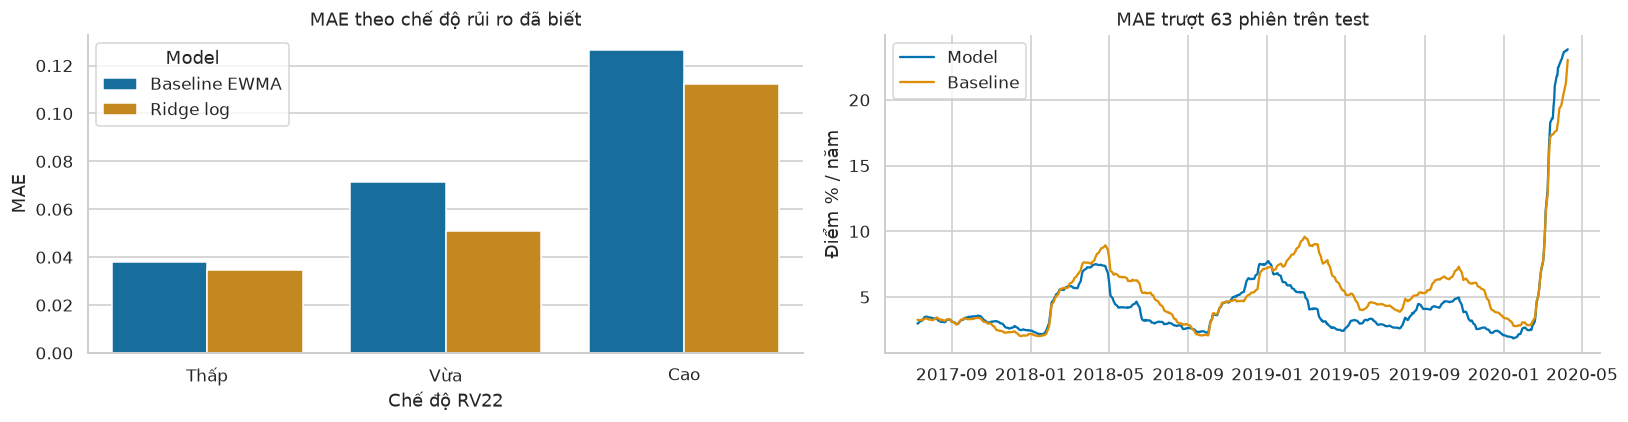

,Năm,Model,Số phiên,RMSE,MAE,R2,QLIKE
0,2017,Baseline EWMA,184,0.0350,0.0297,-0.2536,0.6170
1,2017,Ridge log,184,0.0347,0.0300,-0.2319,0.5038
2,2018,Baseline EWMA,251,0.0806,0.0555,0.2499,0.8926
3,2018,Ridge log,251,0.0770,0.0511,0.3156,0.7617
4,2019,Baseline EWMA,252,0.0692,0.0552,-0.4994,0.5443
5,2019,Ridge log,252,0.0442,0.0315,0.3892,0.3213
6,2020,Baseline EWMA,69,0.3118,0.2108,0.2887,1.7422
7,2020,Ridge log,69,0.3479,0.2184,0.1145,2.8031


In [14]:
thresholds = X.iloc[train_idx]['rv_22'].quantile([1/3, 2/3]).to_numpy()
regime = pd.cut(X.iloc[test_idx]['rv_22'], bins=[-np.inf, *thresholds, np.inf],
                labels=['Thấp', 'Vừa', 'Cao'])
regime_rows = []
for group in ['Thấp', 'Vừa', 'Cao']:
    mask = regime == group
    if mask.sum() < 2:
        continue
    for name in list(dict.fromkeys([selected_baseline, selected_name])):
        pred = pd.Series(test_predictions[name], index=y_test.index)
        regime_rows.append({'Chế độ RV22': group, 'Model': name, 'Số phiên': int(mask.sum()),
                            **regression_metrics(y_test[mask], pred[mask])})
regime_results = pd.DataFrame(regime_rows)
display(regime_results.round(4))
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.barplot(data=regime_results, x='Chế độ RV22', y='MAE', hue='Model', ax=axes[0], errorbar=None)
axes[0].set_title('MAE theo chế độ rủi ro đã biết')
rolling_error = pd.DataFrame({'Model': residual.abs(), 'Baseline': (reference_prediction-y_test).abs()}).rolling(63).mean()
axes[1].plot(rolling_error.index, rolling_error * 100)
axes[1].legend(rolling_error.columns); axes[1].set(title='MAE trượt 63 phiên trên test', ylabel='Điểm % / năm')
plt.tight_layout(); plt.show()
by_year = []
for year in sorted(y_test.index.year.unique()):
    mask = y_test.index.year == year
    for name in list(dict.fromkeys([selected_baseline, selected_name])):
        by_year.append({'Năm': year, 'Model': name, 'Số phiên': int(mask.sum()),
                        **regression_metrics(y_test[mask], np.asarray(test_predictions[name])[mask])})
year_results = pd.DataFrame(by_year)
display(year_results.round(4))

### 5.2. Chênh lệch sai số có bền vững không?

Nhãn 5 phiên liên tiếp chồng lấn, nên bootstrap từng phiên độc lập sẽ quá lạc quan. Ta dùng **circular moving-block bootstrap** (block 20 phiên, 1.000 lần) cho chênh lệch absolute error giữa model và baseline. Chênh lệch âm có lợi cho model. Khoảng bootstrap chỉ là chẩn đoán có điều kiện trên giai đoạn test này; không bảo đảm cho chế độ thị trường mới, nhất là khi test có khủng hoảng.

Một kiểm tra phụ lấy mỗi H phiên để giảm chồng lấn nhãn, báo cáo riêng với số mẫu nhỏ hơn.

,So sánh,Chênh lệch MAE,Bootstrap 2.5%,Bootstrap 97.5%
0,Ridge log − Baseline EWMA,-0.00859,-0.01708,0.00005


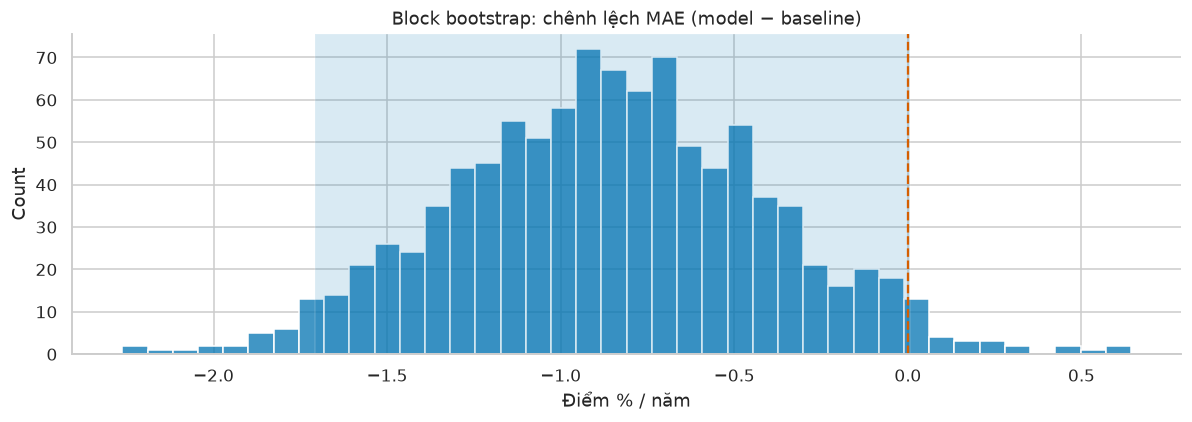

,Số mẫu,RMSE,MAE,R2,QLIKE
Model,,,,,
Baseline EWMA,152,0.1112,0.0632,0.5309,0.8214
Ridge log,152,0.1036,0.0508,0.5923,0.7045


In [15]:
def block_bootstrap_mean(values, block=20, repeats=1000, seed=SEED):
    values = np.asarray(values)
    rng = np.random.default_rng(seed)
    length = len(values)
    draws = np.empty(repeats)
    offsets = np.arange(block)
    for i in range(repeats):
        starts = rng.integers(0, length, size=int(np.ceil(length / block)))
        idx = ((starts[:, None] + offsets) % length).ravel()[:length]
        draws[i] = values[idx].mean()
    return draws

error_delta = (selected_prediction-y_test).abs() - (reference_prediction-y_test).abs()
bootstrap_means = block_bootstrap_mean(error_delta)
ci_low, ci_high = np.quantile(bootstrap_means, [.025, .975])
bootstrap_summary = pd.DataFrame({'So sánh': [f'{selected_name} − {selected_baseline}'],
    'Chênh lệch MAE': [error_delta.mean()], 'Bootstrap 2.5%': [ci_low], 'Bootstrap 97.5%': [ci_high]})
display(bootstrap_summary.round(5))
fig, ax = plt.subplots(figsize=(11, 4))
sns.histplot(bootstrap_means * 100, bins=40, ax=ax)
ax.axvline(0, color='C3', ls='--'); ax.axvspan(ci_low*100, ci_high*100, alpha=.15)
ax.set(title='Block bootstrap: chênh lệch MAE (model − baseline)', xlabel='Điểm % / năm')
plt.tight_layout(); plt.show()
nonoverlap_results = pd.DataFrame([
    {'Model': name, 'Số mẫu': len(y_test.iloc[::H]),
     **regression_metrics(y_test.iloc[::H], np.asarray(test_predictions[name])[::H])}
    for name in list(dict.fromkeys([selected_baseline, selected_name]))
]).set_index('Model')
display(nonoverlap_results.round(4))

### 5.3. Đặc trưng nào có ích cho dự báo?

Permutation importance đo mức tăng MAE khi tráo một cột trên **validation**, dùng mô hình chỉ fit trên train. Không dùng test để chọn lại đặc trưng. Các biến rủi ro tương quan cao có thể thay thế nhau nên mức quan trọng riêng lẻ thấp không có nghĩa là vô dụng. Việc tráo cột cũng phá cấu trúc thời gian, vì vậy đây là chẩn đoán, không phải phân tích nhân quả.

,Đặc trưng,Tăng MAE trung bình,Độ lệch chuẩn
13,rsi_14,0.00539,0.00049
16,range_mean_5,0.00528,0.00039
12,drawdown_252,0.00138,0.00018
4,rv_10,0.00107,0.00015
15,range_1,0.00079,0.00010
8,momentum_5,0.00065,0.00007
6,rv_66,0.00059,0.00013
7,ewma_94,0.00052,0.00010
10,momentum_66,0.00020,0.00003
0,return_1,0.00020,0.00005


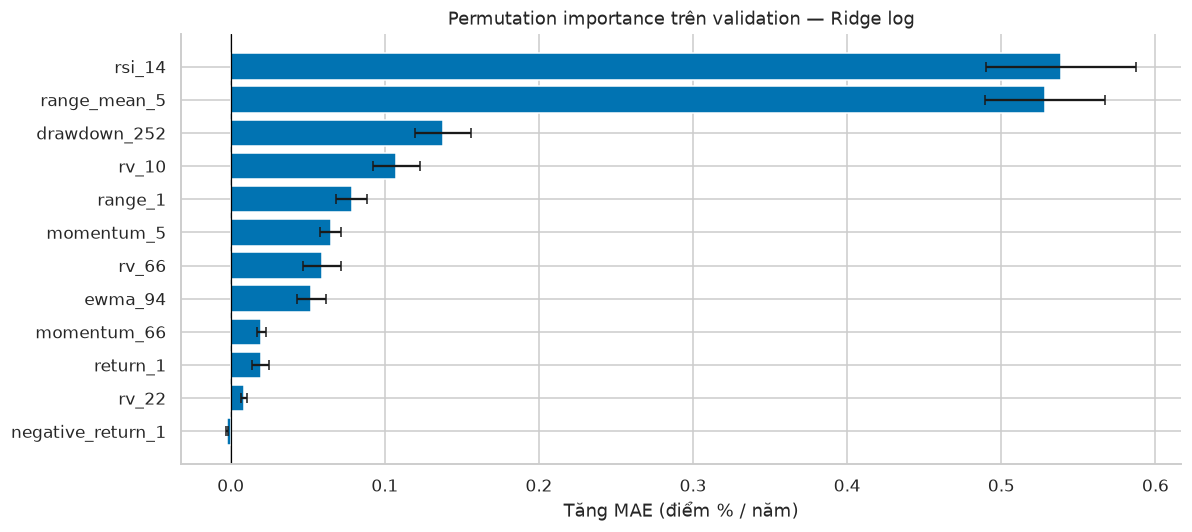

In [16]:
importance = permutation_importance(val_fitted[selected_name], X.iloc[val_idx], y.iloc[val_idx],
    scoring='neg_mean_absolute_error', n_repeats=5, random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({'Đặc trưng': X.columns,
    'Tăng MAE trung bình': importance.importances_mean,
    'Độ lệch chuẩn': importance.importances_std}).sort_values('Tăng MAE trung bình', ascending=False)
display(importance_table.round(5))
shown = importance_table.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(shown['Đặc trưng'], shown['Tăng MAE trung bình'] * 100,
        xerr=shown['Độ lệch chuẩn'] * 100, capsize=3)
ax.axvline(0, color='black', lw=.8)
ax.set(title=f'Permutation importance trên validation — {selected_name}', xlabel='Tăng MAE (điểm % / năm)')
plt.tight_layout(); plt.show()

## 6. Bài toán phụ: ngày mai tăng hay giảm?

Nhãn bằng 1 nếu lợi suất ngày mai > 0, bằng 0 nếu ≤ 0; dòng chưa có ngày mai luôn bị loại. Dùng cùng những mốc thời gian và gap của bài toán rủi ro để dễ kiểm toán, dù mục tiêu này chỉ cần gap một phiên.

So sánh xác suất tăng với **Dummy Prior** (tỷ lệ phiên tăng trên train), Logistic Regression và HistGradientBoosting. Chọn trên validation theo **Brier score** — điểm sai số xác suất, thấp hơn tốt hơn. Accuracy phải được đặt cạnh tỷ lệ lớp, balanced accuracy và AUC. Ngưỡng phân loại cố định 0.5, không chỉnh theo test.

Mục tiêu là xác định tín hiệu có tồn tại hay không, không cố tạo một kết quả đẹp. Notebook không suy ra lợi nhuận từ accuracy và không backtest chiến lược thiếu phí giao dịch.

In [17]:
def direction_metrics(actual, probability):
    prediction = (probability >= .5).astype(int)
    return {'Accuracy': accuracy_score(actual, prediction),
        'Balanced accuracy': balanced_accuracy_score(actual, prediction),
        'ROC AUC': roc_auc_score(actual, probability) if len(np.unique(actual)) == 2 else np.nan,
        'Brier': brier_score_loss(actual, probability)}

class_candidates = {
    'Dummy Prior': DummyClassifier(strategy='prior'),
    'Logistic': make_pipeline(StandardScaler(), LogisticRegression(C=.1, max_iter=1500, random_state=SEED)),
    'HistGB classifier': HistGradientBoostingClassifier(max_iter=100, learning_rate=.04,
        max_leaf_nodes=5, min_samples_leaf=60, l2_regularization=10,
        early_stopping=False, random_state=SEED),
}
class_val_rows = []
for name, estimator in class_candidates.items():
    fitted = clone(estimator).fit(X.iloc[train_idx], y_direction.iloc[train_idx])
    probability = fitted.predict_proba(X.iloc[val_idx])[:, 1]
    class_val_rows.append({'Model': name, **direction_metrics(y_direction.iloc[val_idx], probability)})
class_validation = pd.DataFrame(class_val_rows).set_index('Model').sort_values('Brier')
class_selected = class_validation.index[0]
display(class_validation.round(4))
print('Mô hình hướng đi được khóa trước khi mở test:', class_selected)
class_probabilities, class_test_rows = {}, []
for name in list(dict.fromkeys(['Dummy Prior', class_selected])):
    fitted = clone(class_candidates[name]).fit(X.iloc[dev_idx], y_direction.iloc[dev_idx])
    probability = fitted.predict_proba(X.iloc[test_idx])[:, 1]
    class_probabilities[name] = probability
    class_test_rows.append({'Model': name, **direction_metrics(y_direction.iloc[test_idx], probability)})
class_test = pd.DataFrame(class_test_rows).set_index('Model')
display(class_test.round(4))
display(pd.DataFrame({'Tập': ['Train', 'Validation', 'Test'],
    'Tỷ lệ phiên tăng': [y_direction.iloc[idx].mean() for idx in [train_idx, val_idx, test_idx]],
    'Số phiên': [len(idx) for idx in [train_idx, val_idx, test_idx]]}).round(4))

,Accuracy,Balanced accuracy,ROC AUC,Brier
Model,,,,
Dummy Prior,0.5227,0.5000,0.5000,0.2496
Logistic,0.5200,0.4981,0.5223,0.2501
HistGB classifier,0.5093,0.4965,0.5122,0.2514


Mô hình hướng đi được khóa trước khi mở test: Dummy Prior


,Accuracy,Balanced accuracy,ROC AUC,Brier
Model,,,,
Dummy Prior,0.5595,0.5,0.5,0.2473


,Tập,Tỷ lệ phiên tăng,Số phiên
0,Train,0.5321,3518
1,Validation,0.5227,750
2,Test,0.5595,756


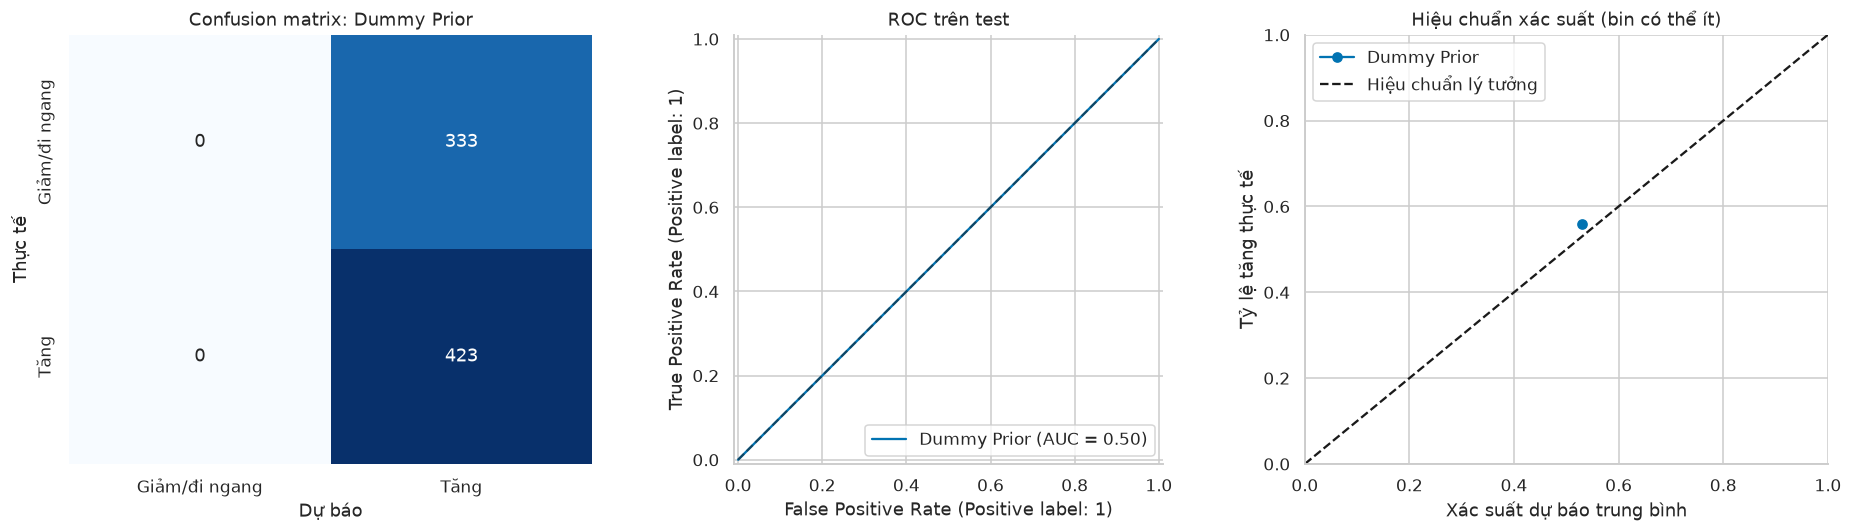

In [18]:
actual_direction = y_direction.iloc[test_idx]
probability = class_probabilities[class_selected]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
cm = confusion_matrix(actual_direction, probability >= .5, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Giảm/đi ngang', 'Tăng'], yticklabels=['Giảm/đi ngang', 'Tăng'])
axes[0].set(title=f'Confusion matrix: {class_selected}', xlabel='Dự báo', ylabel='Thực tế')
for name, probs in class_probabilities.items():
    RocCurveDisplay.from_predictions(actual_direction, probs, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', alpha=.5); axes[1].set_title('ROC trên test')
observed, forecast = calibration_curve(actual_direction, probability, n_bins=8, strategy='quantile')
axes[2].plot(forecast, observed, 'o-', label=class_selected)
axes[2].plot([0, 1], [0, 1], 'k--', label='Hiệu chuẩn lý tưởng')
axes[2].set(title='Hiệu chuẩn xác suất (bin có thể ít)', xlabel='Xác suất dự báo trung bình', ylabel='Tỷ lệ tăng thực tế', xlim=(0, 1), ylim=(0, 1))
axes[2].legend(); plt.tight_layout(); plt.show()

## 7. Tổng hợp insight từ lần chạy này

Phần dưới tạo nhận xét từ số liệu đã tính, phân biệt **mô tả lịch sử**, **dự báo ngoài mẫu** và **giới hạn suy luận**. Nếu mô hình không thắng baseline, đó là kết quả cần báo cáo, không phải lý do đổi lại tập test.

In [19]:
model_row = test_results.loc[selected_name]
base_row = test_results.loc[selected_baseline]
rmse_skill = 1 - model_row['RMSE'] / base_row['RMSE']
qlike_gain = base_row['QLIKE'] - model_row['QLIKE']
class_gain = class_test.loc['Dummy Prior', 'Brier'] - class_test.loc[class_selected, 'Brier']
if selected_name == selected_baseline:
    risk_conclusion = 'Validation chọn chính baseline; chưa có bằng chứng để ưu tiên mô hình phức tạp.'
elif rmse_skill > 0 and qlike_gain > 0:
    risk_conclusion = 'Mô hình cải thiện cả RMSE lẫn QLIKE trên test so với baseline đã chọn; cần kiểm tra thêm độ ổn định ngoài giai đoạn này.'
else:
    risk_conclusion = 'Mô hình không cải thiện đồng thời RMSE và QLIKE trên test; chưa đủ cơ sở thay baseline.'
if selected_name == selected_baseline:
    uncertainty_note = 'Model trùng baseline nên chênh lệch bằng 0 theo định nghĩa.'
elif ci_high < 0:
    uncertainty_note = 'Khoảng block bootstrap của chênh lệch MAE nằm dưới 0 trong giai đoạn test này.'
elif ci_low > 0:
    uncertainty_note = 'Khoảng block bootstrap của chênh lệch MAE nằm trên 0: model có sai số lớn hơn baseline trong giai đoạn test này.'
else:
    uncertainty_note = 'Khoảng block bootstrap cắt 0: chưa phân biệt rõ chênh lệch MAE với nhiễu lấy mẫu.'
insight_table = pd.DataFrame([
    ['Phạm vi', f"{provenance['first_date']} → {provenance['last_date']}; {len(prices):,} phiên; nguồn {DATA_SOURCE}.", 'Không suy rộng thành nhận định thị trường hiện tại.'],
    ['Rủi ro đuôi', f'Excess kurtosis {r.kurt():.2f}; phiên tệ nhất {r.min():.2%}.', 'Giữ dữ liệu cực đoan và đánh giá theo chế độ.'],
    ['Drawdown', f'Mức sụt giảm từ đỉnh lớn nhất {drawdown.min():.2%}.', 'Lợi suất trung bình không mô tả đầy đủ rủi ro nắm giữ.'],
    ['Tính dai dẳng', f'ACF lag 1 của |r| {r.abs().autocorr(1):.3f}, của r {r.autocorr(1):.3f}.', 'Là giả thuyết để kiểm thử, không tự nó chứng minh dự báo tốt.'],
    ['Dự báo rủi ro', f'{selected_name}; RMSE skill {rmse_skill:.2%}; QLIKE cải thiện {qlike_gain:.4f}.', risk_conclusion],
    ['Độ bất định', f'Chênh lệch MAE {error_delta.mean():.4f}; CI bootstrap [{ci_low:.4f}, {ci_high:.4f}].', uncertainty_note],
    ['Hướng đi', f'{class_selected}; AUC {class_test.loc[class_selected, "ROC AUC"]:.3f}; Brier cải thiện {class_gain:.4f}.',
      'Brier thấp hơn baseline ở test.' if class_gain > 0 else 'Chưa cải thiện Brier so với Dummy Prior.'],
], columns=['Chủ đề', 'Bằng chứng', 'Diễn giải / hành động'])
display(insight_table.style.set_properties(**{'white-space': 'normal', 'text-align': 'left'}))
display(Markdown(f'**Kết luận dự báo rủi ro:** {risk_conclusion} **{uncertainty_note}**'))

,Chủ đề,Bằng chứng,Diễn giải / hành động
0,Phạm vi,"2000-01-03 → 2020-04-17; 5,105 phiên; nguồn historical_sample.",Không suy rộng thành nhận định thị trường hiện tại.
1,Rủi ro đuôi,Excess kurtosis 11.03; phiên tệ nhất -11.98%.,Giữ dữ liệu cực đoan và đánh giá theo chế độ.
2,Drawdown,Mức sụt giảm từ đỉnh lớn nhất -56.78%.,Lợi suất trung bình không mô tả đầy đủ rủi ro nắm giữ.
3,Tính dai dẳng,"ACF lag 1 của |r| 0.311, của r -0.115.","Là giả thuyết để kiểm thử, không tự nó chứng minh dự báo tốt."
4,Dự báo rủi ro,Ridge log; RMSE skill -3.92%; QLIKE cải thiện 0.0485.,Mô hình không cải thiện đồng thời RMSE và QLIKE trên test; chưa đủ cơ sở thay baseline.
5,Độ bất định,"Chênh lệch MAE -0.0086; CI bootstrap [-0.0171, 0.0001].",Khoảng block bootstrap cắt 0: chưa phân biệt rõ chênh lệch MAE với nhiễu lấy mẫu.
6,Hướng đi,Dummy Prior; AUC 0.500; Brier cải thiện 0.0000.,Chưa cải thiện Brier so với Dummy Prior.


**Kết luận dự báo rủi ro:** Mô hình không cải thiện đồng thời RMSE và QLIKE trên test; chưa đủ cơ sở thay baseline. **Khoảng block bootstrap cắt 0: chưa phân biệt rõ chênh lệch MAE với nhiễu lấy mẫu.**

### Giới hạn cần giữ khi trình bày kết quả

1. **Dữ liệu và chế độ thị trường:** mẫu mặc định dừng ngày 17/04/2020; tập test bao gồm giai đoạn COVID-19 nhưng không bao gồm các năm sau. Cập nhật dữ liệu và giữ một tập test mới trước khi sử dụng trong thực tế.
2. **Đo lường mục tiêu:** RV từ 5 lợi suất ngày là ước lượng nhiễu; không tương đương realized volatility từ dữ liệu intraday hay implied volatility của VIX. Quy năm 252 chỉ là quy ước.
3. **R² và accuracy:** R² không phải “độ chính xác”. `100 − MAPE` cũng không phải accuracy hợp lệ cho hồi quy. Không suy ra mức an toàn, khả năng sinh lời hoặc mức đòn bẩy phù hợp từ các chỉ số này.
4. **Phụ thuộc thời gian:** gap H ngăn nhãn vượt ranh giới; nó không làm các quan sát độc lập. Block bootstrap có thể vẫn kém tin cậy dưới thay đổi chế độ; nhãn không chồng lấn chỉ là kiểm tra độ nhạy.
5. **Thử nhiều mô hình:** một validation có thể bị lựa chọn quá mức. Cross-validation trên train là chẩn đoán; cần nested walk-forward hoặc kiểm thử tiến về phía trước trước khi triển khai.
6. **Giải thích và rủi ro:** tương quan, heatmap và permutation importance không chứng minh nhân quả. Dự báo điểm không đủ để tính VaR/Expected Shortfall đáng tin cậy nếu chưa có mô hình phân phối và backtest độ bao phủ.
7. **Thời điểm thực thi:** đặc trưng dùng giá đóng cửa hôm nay; không được giả định mua/bán chính xác ở mức giá này sau khi đã biết nó. Notebook không tuyên bố lợi nhuận giao dịch.

### Hướng mở rộng có tiêu chí dừng

- Ưu tiên cập nhật dữ liệu và đánh giá walk-forward nhiều giai đoạn trước khi tăng kích thước mạng nơ-ron.
- Nếu muốn dự báo rủi ro đuôi, thử quantile regression, kiểm tra coverage và so với baseline tương ứng.
- Chỉ thêm VIX, lãi suất hay biến vĩ mô khi có dấu thời gian công bố và dữ liệu point-in-time để tránh look-ahead bias.
- Nếu nhiều mô hình vẫn không cải thiện baseline ổn định, giữ baseline và báo cáo giới hạn của tín hiệu giá.

In [20]:
# Xuất kết quả có provenance để đối chiếu; không ghi đè file nguồn của người dùng.
prediction_export = pd.DataFrame({'actual_future_rv': y_test,
    'selected_predicted_rv': selected_prediction, 'baseline_predicted_rv': reference_prediction,
    'actual_up_next': actual_direction, 'predicted_probability_up': probability})
validation_results.to_csv(ARTIFACT_DIR / 'validation_regression.csv')
test_results.to_csv(ARTIFACT_DIR / 'test_regression.csv')
class_validation.to_csv(ARTIFACT_DIR / 'validation_classification.csv')
class_test.to_csv(ARTIFACT_DIR / 'test_classification.csv')
prediction_export.to_csv(ARTIFACT_DIR / 'test_predictions.csv')
regime_results.to_csv(ARTIFACT_DIR / 'test_by_regime.csv', index=False)
year_results.to_csv(ARTIFACT_DIR / 'test_by_year.csv', index=False)
cv_results.to_csv(ARTIFACT_DIR / 'train_time_series_cv.csv', index=False)
insight_table.to_csv(ARTIFACT_DIR / 'insights.csv', index=False)
importance_table.to_csv(ARTIFACT_DIR / 'validation_importance.csv', index=False)
report = {'data': provenance, 'versions': versions, 'seed': SEED, 'horizon': H,
          'selected_model': selected_name, 'selected_baseline': selected_baseline,
          'selected_classifier': class_selected, 'rmse_skill_vs_baseline': float(rmse_skill),
          'mae_delta_bootstrap_ci': [float(ci_low), float(ci_high)],
          'split': split_table.astype(str).to_dict(orient='records')}
(ARTIFACT_DIR / 'run_report.json').write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
assert prediction_export.notna().all().all()
assert (prediction_export[['selected_predicted_rv', 'baseline_predicted_rv']] > 0).all().all()
assert prediction_export['predicted_probability_up'].between(0, 1).all()
print('Đã hoàn tất tất cả bước. Kết quả:', ARTIFACT_DIR.resolve())
print('Kiểm tra nhãn, ranh giới thời gian, tính nhân quả, dự báo dương và xác suất hợp lệ: PASS.')

Đã hoàn tất tất cả bước. Kết quả: /workspace/setup/data-science/notebook-run
Kiểm tra nhãn, ranh giới thời gian, tính nhân quả, dự báo dương và xác suất hợp lệ: PASS.


## Tái lập và nguồn tham khảo

**Chạy:** khởi động kernel Python đã cài các thư viện ở bảng phiên bản, chọn **Restart Kernel → Run All**. Các thư viện cần thiết: NumPy, pandas, SciPy, Matplotlib, seaborn, scikit-learn, PyTorch, Jupyter/IPython; `yfinance` chỉ cần khi chọn nguồn Yahoo. Trong môi trường cloud hiện tại, dùng `/workspace/.venvs/data-science/bin/python`.

Mặc định notebook tải dữ liệu qua HTTPS, xác minh SHA-256, rồi cache trong `outputs/sp500_research`. Có thể đổi nơi lưu bằng biến `SP500_OUTPUT_DIR`. Cache chỉ tái sử dụng nếu checksum khớp. Đổi nguồn bằng `SP500_DATA_SOURCE=csv` cùng `SP500_CSV=/duong-dan/tep.csv`, hoặc `SP500_DATA_SOURCE=yahoo`.

- [Vega Datasets: S&P 500 daily sample, bản đã ghim](https://github.com/vega/vega-datasets/blob/5448e25297c8f705be78e879d5423d55d04dc6f1/data/sp500-2000.csv). Bộ mẫu lưu giá lịch sử, không phải nguồn dữ liệu thị trường trực tiếp.
- [yfinance: download và ý nghĩa tham số](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html).
- [scikit-learn: TimeSeriesSplit và gap](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).
- [scikit-learn: permutation importance và giới hạn với đặc trưng tương quan](https://scikit-learn.org/stable/modules/permutation_importance.html).
- Corsi (2009), *A Simple Approximate Long-Memory Model of Realized Volatility*. HAR ở đây là biến thể dùng RV từ lợi suất ngày, không sao chép nguyên mô hình intraday của bài báo.

**Nguyên tắc trình bày:** giữ cả kết quả tốt và xấu, ghi rõ nguồn/giai đoạn, phân biệt mô tả với dự báo, và không dùng tập test như một tập validation thứ hai.